<a href="https://colab.research.google.com/github/samir7501/Lip-Reading-System/blob/main/Lip_Reading_System_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import sys
import torch

print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available")
    print("Please select GPU in Runtime settings.")

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch Version: 2.14.1+cu130
GPU Available: Tesla T4


In [7]:
!pip install -q opencv-python-headless
!pip install -q mediapipe
!pip install -q numpy pandas matplotlib
!pip install -q jiwer tqdm

In [8]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
import torch
import jiwer

print("All libraries imported successfully!")
print("GPU:", torch.cuda.is_available())

All libraries imported successfully!
GPU: True


In [9]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import os

BASE_DIR = "/content/drive/MyDrive/Lip_Reading_System"

folders = [
    "dataset/raw",
    "dataset/processed",
    "dataset/transcripts",
    "models",
    "results",
    "notebooks"
]

for folder in folders:
    path = os.path.join(BASE_DIR, folder)
    os.makedirs(path, exist_ok=True)

print("Project folders created successfully!")

print("Project Location:", BASE_DIR)

Project folders created successfully!
Project Location: /content/drive/MyDrive/Lip_Reading_System


In [11]:
import os

VIDEO_DIR = BASE_DIR + "/dataset/raw"
VIDEO_ZIP = VIDEO_DIR + "/s1.mpg_vcd.zip"

video_url = (
    "https://spandh.dcs.shef.ac.uk/"
    "gridcorpus/s1/video/s1.mpg_vcd.zip"
)

!wget -c -O "$VIDEO_ZIP" "$video_url"

print("Video download completed!")

--2026-11-06 19:11:05--  https://spandh.dcs.shef.ac.uk/gridcorpus/s1/video/s1.mpg_vcd.zip
Resolving spandh.dcs.shef.ac.uk (spandh.dcs.shef.ac.uk)... 143.167.8.2
Connecting to spandh.dcs.shef.ac.uk (spandh.dcs.shef.ac.uk)|143.167.8.2|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 422746353 (403M) [application/zip]
Saving to: ‘/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1.mpg_vcd.zip’

/content/drive/MyDr 100%[===================>] 403.16M  23.6MB/s    in 19s     

2026-11-06 19:11:25 (21.6 MB/s) - ‘/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1.mpg_vcd.zip’ saved [422746353/422746353]

Video download completed!


In [12]:
ALIGN_DIR = BASE_DIR + "/dataset/transcripts"
ALIGN_FILE = ALIGN_DIR + "/s1.tar"

alignment_url = (
    "https://spandh.dcs.shef.ac.uk/"
    "gridcorpus/s1/align/s1.tar"
)

!wget -c -O "$ALIGN_FILE" "$alignment_url"

print("Alignment download completed!")

--2026-11-06 19:12:08--  https://spandh.dcs.shef.ac.uk/gridcorpus/s1/align/s1.tar
Resolving spandh.dcs.shef.ac.uk (spandh.dcs.shef.ac.uk)... 143.167.8.2
Connecting to spandh.dcs.shef.ac.uk (spandh.dcs.shef.ac.uk)|143.167.8.2|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1034240 (1010K) [application/x-tar]
Saving to: ‘/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/s1.tar’

/content/drive/MyDr 100%[===================>]   1010K  1.26MB/s    in 0.8s    

2026-11-06 19:12:10 (1.26 MB/s) - ‘/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/s1.tar’ saved [1034240/1034240]

Alignment download completed!


In [13]:
import zipfile
import tarfile

# Extract video archive
with zipfile.ZipFile(VIDEO_ZIP, 'r') as zip_ref:
    zip_ref.extractall(VIDEO_DIR)

print("Videos extracted successfully!")

# Extract alignment archive
with tarfile.open(ALIGN_FILE, 'r') as tar_ref:
    tar_ref.extractall(ALIGN_DIR)

print("Transcripts extracted successfully!")

Videos extracted successfully!


/tmp/ipykernel_570/3649465063.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_ref.extractall(ALIGN_DIR)


Transcripts extracted successfully!


In [14]:
def count_files(folder):
    count = 0

    for root, dirs, files in os.walk(folder):
        count += len(files)

    return count

print("Video files:",
      count_files(VIDEO_DIR))

print("Alignment files:",
      count_files(ALIGN_DIR))

Video files: 1002
Alignment files: 1001


Number of MPG videos: 1000


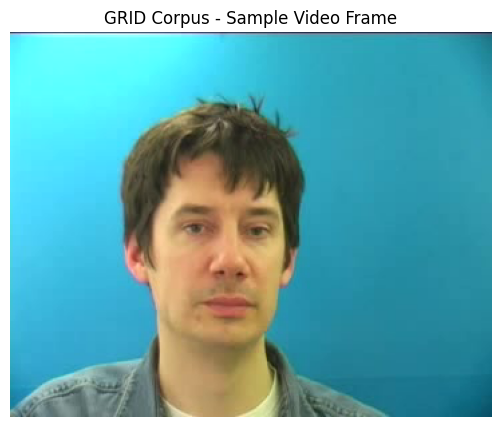

In [15]:
import glob
import cv2
import matplotlib.pyplot as plt

video_files = glob.glob(
    VIDEO_DIR + "/**/*.mpg",
    recursive=True
)

print("Number of MPG videos:", len(video_files))

if video_files:
    cap = cv2.VideoCapture(video_files[0])

    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(8, 5))
        plt.imshow(frame)
        plt.title("GRID Corpus - Sample Video Frame")
        plt.axis("off")
        plt.show()

    cap.release()
else:
    print("No MPG files found. Check extracted folders.")

In [16]:
import os

BASE_DIR = "/content/drive/MyDrive/Lip_Reading_System"

RAW_DIR = BASE_DIR + "/dataset/raw"
PROCESSED_DIR = BASE_DIR + "/dataset/processed"
TRANSCRIPT_DIR = BASE_DIR + "/dataset/transcripts"

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Raw dataset:", RAW_DIR)
print("Processed dataset:", PROCESSED_DIR)
print("Folders ready!")

Raw dataset: /content/drive/MyDrive/Lip_Reading_System/dataset/raw
Processed dataset: /content/drive/MyDrive/Lip_Reading_System/dataset/processed
Folders ready!


In [17]:
import glob

video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

print("Total videos found:", len(video_files))

for video in video_files[:10]:
    print(video)

Total videos found: 1000
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/swio1s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/prii9a.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/sgwp9s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/lwws5s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/bbal8p.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/pwwrzp.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/pwwezn.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/sgivzn.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/swwi9s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/lgwtzn.mpg


In [22]:
!pip install --no-cache-dir mediapipe==0.10.35

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 34.9 MB/s  0:00:00


In [1]:
import mediapipe as mp

print("Version:", mp.__version__)
print("Solutions available:", hasattr(mp, "solutions"))

Version: 0.10.35
Solutions available: False


In [2]:
import os
import urllib.request

MODEL_DIR = "/content/face_model"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = MODEL_DIR + "/face_landmarker.task"

MODEL_URL = (
    "https://storage.googleapis.com/"
    "mediapipe-models/face_landmarker/"
    "face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

print("Model downloaded:", os.path.exists(MODEL_PATH))

Model downloaded: True


In [3]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False
)

face_landmarker = FaceLandmarker.create_from_options(options)

print("Face Landmarker initialized successfully!")

Face Landmarker initialized successfully!


In [5]:
import cv2
import numpy as np
import mediapipe as mp

MOUTH_LANDMARKS = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291,
    409, 270, 269, 267, 0,
    37, 39, 40, 185, 76, 77,
    78, 191, 95, 88, 178, 87,
    14, 317, 402, 318, 324, 308
]

def extract_mouth(frame, face_landmarker):

    height, width, _ = frame.shape

    rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    results = face_landmarker.detect(mp_image)

    if not results.face_landmarks:
        return None

    landmarks = results.face_landmarks[0]

    points = []

    for index in MOUTH_LANDMARKS:

        x = int(landmarks[index].x * width)
        y = int(landmarks[index].y * height)

        points.append([x, y])

    points = np.array(points)

    x_min, y_min = points.min(axis=0)
    x_max, y_max = points.max(axis=0)

    center_x = (x_min + x_max) // 2
    center_y = (y_min + y_max) // 2

    mouth_width = x_max - x_min
    mouth_height = y_max - y_min

    side = int(max(
        mouth_width * 1.8,
        mouth_height * 2.5,
        30
    ))

    x1 = max(0, center_x - side // 2)
    y1 = max(0, center_y - side // 2)

    x2 = min(width, center_x + side // 2)
    y2 = min(height, center_y + side // 2)

    mouth = frame[y1:y2, x1:x2]

    if mouth.size == 0:
        return None

    mouth = cv2.cvtColor(
        mouth,
        cv2.COLOR_BGR2GRAY
    )

    mouth = cv2.resize(mouth, (96, 96))

    mouth = mouth.astype(np.float32) / 255.0

    return mouth

In [6]:
import glob
import matplotlib.pyplot as plt

video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

video_path = video_files[0]

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:

    mouth = extract_mouth(frame, face_landmarker)

    if mouth is not None:

        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title("Original Video Frame")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(mouth, cmap="gray")
        plt.title("Extracted Mouth")
        plt.axis("off")

        plt.show()

    else:
        print("Face not detected!")

cap.release()

NameError: name 'RAW_DIR' is not defined

In [7]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import os
import glob

BASE_DIR = "/content/drive/MyDrive/Lip_Reading_System"

RAW_DIR = os.path.join(
    BASE_DIR, "dataset", "raw"
)

PROCESSED_DIR = os.path.join(
    BASE_DIR, "dataset", "processed"
)

TRANSCRIPT_DIR = os.path.join(
    BASE_DIR, "dataset", "transcripts"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("RAW_DIR:", RAW_DIR)
print("Project directory exists:", os.path.exists(BASE_DIR))
print("Raw dataset exists:", os.path.exists(RAW_DIR))

RAW_DIR: /content/drive/MyDrive/Lip_Reading_System/dataset/raw
Project directory exists: True
Raw dataset exists: True


In [9]:
video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

print("Total GRID videos:", len(video_files))

for video in video_files[:10]:
    print(video)

Total GRID videos: 1000
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/swio1s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/prii9a.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/sgwp9s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/lwws5s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/bbal8p.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/pwwrzp.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/pwwezn.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/sgivzn.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/swwi9s.mpg
/content/drive/MyDrive/Lip_Reading_System/dataset/raw/s1/lgwtzn.mpg


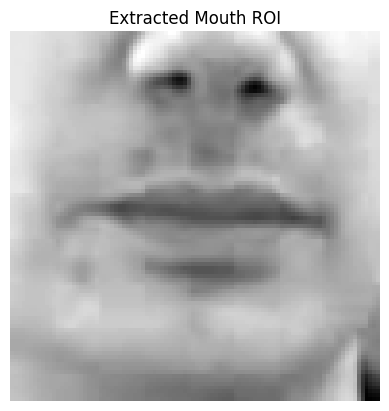

In [10]:
video_path = video_files[0]

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:
    mouth = extract_mouth(frame, face_landmarker)

    if mouth is not None:
        plt.imshow(mouth, cmap="gray")
        plt.title("Extracted Mouth ROI")
        plt.axis("off")
        plt.show()
    else:
        print("Face not detected")

cap.release()

In [11]:
import glob
import os
import numpy as np

video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

print("Total GRID videos found:", len(video_files))

OUTPUT_DIR = PROCESSED_DIR + "/speaker_1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Processed folder:", OUTPUT_DIR)

Total GRID videos found: 1000
Processed folder: /content/drive/MyDrive/Lip_Reading_System/dataset/processed/speaker_1


Mouth extraction successful!
Mouth image shape: (96, 96)
Minimum pixel value: 0.15686275
Maximum pixel value: 0.7647059


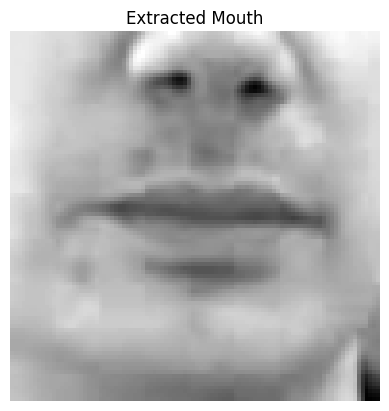

In [12]:
video_path = video_files[0]

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:
    mouth = extract_mouth(frame, face_landmarker)

    if mouth is not None:
        print("Mouth extraction successful!")
        print("Mouth image shape:", mouth.shape)
        print("Minimum pixel value:", mouth.min())
        print("Maximum pixel value:", mouth.max())

        plt.imshow(mouth, cmap="gray")
        plt.title("Extracted Mouth")
        plt.axis("off")
        plt.show()
    else:
        print("No face detected in this frame.")

cap.release()

In [13]:
import os
import glob

ALIGN_DIR = BASE_DIR + "/dataset/transcripts"

align_files = glob.glob(
    ALIGN_DIR + "/**/*.align",
    recursive=True
)

print("Total alignment files:", len(align_files))

for file in align_files[:10]:
    print(file)

Total alignment files: 1000
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf2n.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf3s.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf4p.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf5a.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbal6n.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbal7s.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbal8p.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbal9a.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbas1s.align
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbas2p.align


In [14]:
if len(align_files) > 0:

    sample_align = align_files[0]

    print("Alignment file:", sample_align)

    with open(sample_align, "r") as f:
        content = f.read()

    print("\nAlignment content:\n")
    print(content[:2000])

else:
    print("No .align files found. Check your extracted alignment archive.")

Alignment file: /content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf2n.align

Alignment content:

0 23750 sil
23750 29500 bin
29500 34000 blue
34000 35500 at
35500 41000 f
41000 47250 two
47250 53000 now
53000 74500 sil



In [15]:
PROCESSED_DIR = BASE_DIR + "/dataset/processed"

npy_files = glob.glob(
    PROCESSED_DIR + "/**/*.npy",
    recursive=True
)

print("Processed mouth sequences:", len(npy_files))

for file in npy_files[:5]:
    data = np.load(file)
    print(os.path.basename(file), data.shape)

Processed mouth sequences: 0


In [16]:
video_map = {
    os.path.splitext(os.path.basename(v))[0]: v
    for v in video_files
}

align_map = {
    os.path.splitext(os.path.basename(a))[0]: a
    for a in align_files
}

common_ids = sorted(
    set(video_map.keys()) & set(align_map.keys())
)

print("Videos:", len(video_map))
print("Alignment files:", len(align_map))
print("Matched pairs:", len(common_ids))

print("\nFirst 10 matched IDs:")

for item in common_ids[:10]:
    print(item)

Videos: 1000
Alignment files: 1000
Matched pairs: 1000

First 10 matched IDs:
bbaf2n
bbaf3s
bbaf4p
bbaf5a
bbal6n
bbal7s
bbal8p
bbal9a
bbas1s
bbas2p


In [17]:
import os
import glob

align_files = glob.glob(
    TRANSCRIPT_DIR + "/**/*.align",
    recursive=True
)

print("Alignment files:", len(align_files))

sample_align = align_files[0]

print("\nFile:", sample_align)
print("\nActual alignment content:\n")

with open(sample_align, "r") as f:
    for i, line in enumerate(f):
        print(line.strip())

        if i >= 12:
            break

Alignment files: 1000

File: /content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf2n.align

Actual alignment content:

0 23750 sil
23750 29500 bin
29500 34000 blue
34000 35500 at
35500 41000 f
41000 47250 two
47250 53000 now
53000 74500 sil


In [18]:
import re

SILENCE_WORDS = {
    "sil", "sp", "spn", "silence", ""
}

def read_grid_transcript(align_path):

    words = []

    with open(align_path, "r", encoding="utf-8") as file:

        for line in file:

            parts = line.strip().split()

            # Ignore empty or invalid lines
            if len(parts) < 3:
                continue

            word = parts[-1].lower()

            # Remove silence
            if word in SILENCE_WORDS:
                continue

            words.append(word)

    transcript = " ".join(words)

    return transcript

In [19]:
sample_transcript = read_grid_transcript(
    sample_align
)

print("Alignment file:", sample_align)
print("Extracted sentence:", sample_transcript)

Alignment file: /content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf2n.align
Extracted sentence: bin blue at f two now


In [20]:
import os
import glob
import pandas as pd

def normalize_id(path):

    name = os.path.splitext(
        os.path.basename(path)
    )[0]

    name = re.sub(
        r"^s\d+_",
        "",
        name,
        flags=re.IGNORECASE
    )

    return name.lower()


video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

align_files = glob.glob(
    TRANSCRIPT_DIR + "/**/*.align",
    recursive=True
)

video_map = {
    normalize_id(path): path
    for path in video_files
}

align_map = {
    normalize_id(path): path
    for path in align_files
}

common_ids = sorted(
    set(video_map.keys()) &
    set(align_map.keys())
)

records = []

for video_id in common_ids:

    video_path = video_map[video_id]
    align_path = align_map[video_id]

    transcript = read_grid_transcript(
        align_path
    )

    if transcript:

        records.append({
            "video_id": video_id,
            "video_path": video_path,
            "align_path": align_path,
            "transcript": transcript
        })

dataset_df = pd.DataFrame(records)

print("Total videos:", len(video_files))
print("Total alignments:", len(align_files))
print("Matched records:", len(dataset_df))

print("\nSample transcripts:")

print(
    dataset_df[
        ["video_id", "transcript"]
    ].head(10).to_string(index=False)
)

Total videos: 1000
Total alignments: 1000
Matched records: 1000

Sample transcripts:
video_id                 transcript
  bbaf2n      bin blue at f two now
  bbaf3s   bin blue at f three soon
  bbaf4p  bin blue at f four please
  bbaf5a   bin blue at f five again
  bbal6n      bin blue at l six now
  bbal7s   bin blue at l seven soon
  bbal8p bin blue at l eight please
  bbal9a   bin blue at l nine again
  bbas1s     bin blue at s one soon
  bbas2p   bin blue at s two please


In [21]:
CSV_PATH = (
    BASE_DIR +
    "/dataset/transcripts/grid_transcripts.csv"
)

dataset_df.to_csv(
    CSV_PATH,
    index=False
)

print("Transcript dataset saved!")
print(CSV_PATH)

Transcript dataset saved!
/content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/grid_transcripts.csv


In [22]:
import json
import string

characters = string.ascii_lowercase + " '"

char_to_idx = {
    char: idx + 1
    for idx, char in enumerate(characters)
}

idx_to_char = {
    idx: char
    for char, idx in char_to_idx.items()
}

print("Vocabulary size:", len(char_to_idx) + 1)
print("Character mapping:", char_to_idx)

Vocabulary size: 29
Character mapping: {'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, ' ': 27, "'": 28}


In [23]:
def encode_transcript(text):

    text = text.lower()

    encoded = []

    for char in text:

        if char in char_to_idx:
            encoded.append(char_to_idx[char])
        else:
            raise ValueError(
                f"Unknown character: {char}"
            )

    return encoded


dataset_df["encoded_text"] = dataset_df[
    "transcript"
].apply(encode_transcript)

print(dataset_df[
    ["transcript", "encoded_text"]
].head(10))

                   transcript  \
0       bin blue at f two now   
1    bin blue at f three soon   
2   bin blue at f four please   
3    bin blue at f five again   
4       bin blue at l six now   
5    bin blue at l seven soon   
6  bin blue at l eight please   
7    bin blue at l nine again   
8      bin blue at s one soon   
9    bin blue at s two please   

                                        encoded_text  
0  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 6,...  
1  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 6,...  
2  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 6,...  
3  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 6,...  
4  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 12...  
5  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 12...  
6  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 12...  
7  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 12...  
8  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 19...  
9  [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 19...  


In [24]:
VOCAB_PATH = (
    BASE_DIR +
    "/dataset/transcripts/vocabulary.json"
)

with open(VOCAB_PATH, "w") as f:

    json.dump(
        {
            "char_to_idx": char_to_idx,
            "idx_to_char": {
                str(k): v
                for k, v in idx_to_char.items()
            },
            "blank_index": 0
        },
        f,
        indent=4
    )

print("Vocabulary saved successfully!")

Vocabulary saved successfully!


In [25]:
PROCESSED_DIR = BASE_DIR + "/dataset/processed"

npy_files = glob.glob(
    PROCESSED_DIR + "/**/*.npy",
    recursive=True
)

npy_map = {
    normalize_id(path): path
    for path in npy_files
    if os.path.basename(path) != "preprocessing_results.npy"
}

dataset_df["mouth_path"] = dataset_df[
    "video_id"
].map(npy_map)

print("Total transcript records:", len(dataset_df))
print("Available mouth sequences:", dataset_df["mouth_path"].notna().sum())
print("Missing mouth sequences:", dataset_df["mouth_path"].isna().sum())

Total transcript records: 1000
Available mouth sequences: 0
Missing mouth sequences: 1000


In [26]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from tqdm.auto import tqdm

BASE_DIR = "/content/drive/MyDrive/Lip_Reading_System"

RAW_DIR = BASE_DIR + "/dataset/raw"
PROCESSED_DIR = BASE_DIR + "/dataset/processed"
TRANSCRIPT_DIR = BASE_DIR + "/dataset/transcripts"

OUTPUT_DIR = PROCESSED_DIR + "/speaker_1"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project paths initialized!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project paths initialized!


In [27]:
import urllib.request

MODEL_PATH = "/content/face_landmarker.task"

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=RunningMode.IMAGE,
    num_faces=1
)

face_landmarker = FaceLandmarker.create_from_options(options)

print("Face Landmarker ready!")

Face Landmarker ready!


In [28]:
MOUTH_LANDMARKS = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291,
    409, 270, 269, 267, 0,
    37, 39, 40, 185, 76, 77,
    78, 191, 95, 88, 178, 87,
    14, 317, 402, 318, 324, 308
]

def extract_mouth(frame, face_landmarker):

    height, width = frame.shape[:2]

    rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    results = face_landmarker.detect(mp_image)

    if not results.face_landmarks:
        return None

    landmarks = results.face_landmarks[0]

    points = np.array([
        [
            int(landmarks[i].x * width),
            int(landmarks[i].y * height)
        ]
        for i in MOUTH_LANDMARKS
    ])

    x_min, y_min = points.min(axis=0)
    x_max, y_max = points.max(axis=0)

    center_x = (x_min + x_max) // 2
    center_y = (y_min + y_max) // 2

    side = int(max(
        (x_max - x_min) * 1.8,
        (y_max - y_min) * 2.5,
        30
    ))

    x1 = max(0, center_x - side // 2)
    y1 = max(0, center_y - side // 2)

    x2 = min(width, center_x + side // 2)
    y2 = min(height, center_y + side // 2)

    mouth = frame[y1:y2, x1:x2]

    if mouth.size == 0:
        return None

    mouth = cv2.cvtColor(
        mouth,
        cv2.COLOR_BGR2GRAY
    )

    mouth = cv2.resize(mouth, (96, 96))

    return mouth.astype(np.float32) / 255.0

print("Mouth extraction function ready!")

Mouth extraction function ready!


In [29]:
video_files = glob.glob(
    RAW_DIR + "/**/*.mpg",
    recursive=True
)

print("Videos found:", len(video_files))

def normalize_id(path):
    name = os.path.splitext(
        os.path.basename(path)
    )[0]

    if "_" in name:
        name = name.split("_", 1)[1]

    return name.lower()


successful = 0
failed = 0

for video_path in tqdm(video_files):

    video_id = normalize_id(video_path)

    save_path = os.path.join(
        OUTPUT_DIR,
        video_id + ".npy"
    )

    # Skip already processed videos
    if os.path.exists(save_path):
        successful += 1
        continue

    cap = cv2.VideoCapture(video_path)

    mouth_frames = []

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        mouth = extract_mouth(
            frame,
            face_landmarker
        )

        if mouth is not None:
            mouth_frames.append(mouth)

    cap.release()

    if len(mouth_frames) > 0:

        sequence = np.stack(mouth_frames)

        np.save(
            save_path,
            sequence.astype(np.float32)
        )

        successful += 1

    else:
        failed += 1

print("\nProcessing completed!")
print("Successful:", successful)
print("Failed:", failed)

Videos found: 1000


  0%|          | 0/1000 [00:00<?, ?it/s]


Processing completed!
Successful: 1000
Failed: 0


In [30]:
npy_files = glob.glob(
    OUTPUT_DIR + "/*.npy"
)

print("Total processed sequences:", len(npy_files))

if npy_files:

    sample = np.load(npy_files[0])

    print("Sample filename:", os.path.basename(npy_files[0]))
    print("Sequence shape:", sample.shape)
    print("Minimum:", sample.min())
    print("Maximum:", sample.max())

Total processed sequences: 1000
Sample filename: swio1s.npy
Sequence shape: (75, 96, 96)
Minimum: 0.09803922
Maximum: 0.8039216


In [31]:
def read_grid_transcript(align_path):

    words = []

    with open(align_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) < 3:
                continue

            word = parts[-1].lower()

            if word not in {"sil", "sp", "spn"}:
                words.append(word)

    return " ".join(words)


align_files = glob.glob(
    TRANSCRIPT_DIR + "/**/*.align",
    recursive=True
)

video_map = {
    normalize_id(v): v
    for v in video_files
}

align_map = {
    normalize_id(a): a
    for a in align_files
}

records = []

for video_id in sorted(
    set(video_map) & set(align_map)
):

    transcript = read_grid_transcript(
        align_map[video_id]
    )

    mouth_path = os.path.join(
        OUTPUT_DIR,
        video_id + ".npy"
    )

    if transcript and os.path.exists(mouth_path):

        records.append({
            "video_id": video_id,
            "video_path": video_map[video_id],
            "transcript": transcript,
            "mouth_path": mouth_path
        })

dataset_df = pd.DataFrame(records)

print("Complete training records:", len(dataset_df))

print(
    dataset_df[
        ["video_id", "transcript"]
    ].head()
)

Complete training records: 1000
  video_id                 transcript
0   bbaf2n      bin blue at f two now
1   bbaf3s   bin blue at f three soon
2   bbaf4p  bin blue at f four please
3   bbaf5a   bin blue at f five again
4   bbal6n      bin blue at l six now


In [32]:
import string
import json

characters = string.ascii_lowercase + " '"

char_to_idx = {
    char: idx + 1
    for idx, char in enumerate(characters)
}

idx_to_char = {
    idx: char
    for char, idx in char_to_idx.items()
}

def encode_transcript(text):

    encoded = []

    for char in text.lower():

        if char not in char_to_idx:
            raise ValueError(
                f"Unknown character: {char}"
            )

        encoded.append(char_to_idx[char])

    return encoded


dataset_df["encoded_text"] = dataset_df[
    "transcript"
].apply(encode_transcript)

VOCAB_PATH = (
    TRANSCRIPT_DIR + "/vocabulary.json"
)

with open(VOCAB_PATH, "w") as f:

    json.dump(
        {
            "char_to_idx": char_to_idx,
            "blank_index": 0
        },
        f,
        indent=4
    )

print("Vocabulary created!")
print("Number of characters:", len(char_to_idx))
print("CTC blank index: 0")

Vocabulary created!
Number of characters: 28
CTC blank index: 0


In [33]:
import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader,
    random_split
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
GPU available: True


In [34]:
class LipReadingDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        # Load mouth sequence
        frames = np.load(
            row["mouth_path"]
        )

        frames = torch.tensor(
            frames,
            dtype=torch.float32
        )

        # Shape: (T, 96, 96)
        # Add channel dimension
        frames = frames.unsqueeze(1)

        # Shape: (T, 1, 96, 96)
        target = torch.tensor(
            row["encoded_text"],
            dtype=torch.long
        )

        return frames, target

In [35]:
def collate_fn(batch):

    videos, targets = zip(*batch)

    batch_size = len(videos)

    frame_lengths = torch.tensor(
        [len(v) for v in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [len(t) for t in targets],
        dtype=torch.long
    )

    max_frames = max(frame_lengths).item()

    padded_videos = torch.zeros(
        batch_size,
        max_frames,
        1,
        96,
        96
    )

    for i, video in enumerate(videos):

        padded_videos[
            i, :len(video)
        ] = video

    concatenated_targets = torch.cat(targets)

    return (
        padded_videos,
        concatenated_targets,
        frame_lengths,
        target_lengths
    )

In [36]:
from torch.utils.data import random_split

if len(dataset_df) < 2:
    raise ValueError(
        "Not enough processed videos. "
        "Complete video preprocessing first."
    )

full_dataset = LipReadingDataset(dataset_df)

train_size = int(
    0.8 * len(full_dataset)
)

val_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 800
Validation samples: 200


In [37]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("Training DataLoader ready!")
print("Validation DataLoader ready!")

Training DataLoader ready!
Validation DataLoader ready!


In [38]:
videos, targets, frame_lengths, target_lengths = next(
    iter(train_loader)
)

print("Video batch shape:", videos.shape)
print("Target shape:", targets.shape)
print("Frame lengths:", frame_lengths)
print("Target lengths:", target_lengths)

print("DataLoader test successful!")

Video batch shape: torch.Size([4, 75, 1, 96, 96])
Target shape: torch.Size([92])
Frame lengths: tensor([75, 75, 75, 75])
Target lengths: tensor([22, 22, 23, 25])
DataLoader test successful!


In [39]:
import os
import glob
import numpy as np

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "Lip_Reading_System/dataset/processed/speaker_1"
)

npy_files = glob.glob(
    OUTPUT_DIR + "/*.npy"
)

print("Actual NPY files:", len(npy_files))

print("Dataset records:",
      len(dataset_df) if "dataset_df" in globals() else "Not defined")

print("Training dataset:",
      len(train_dataset) if "train_dataset" in globals() else "Not defined")

print("Validation dataset:",
      len(val_dataset) if "val_dataset" in globals() else "Not defined")

if npy_files:
    sample = np.load(npy_files[0])
    print("Sample shape:", sample.shape)

Actual NPY files: 1000
Dataset records: 1000
Training dataset: 800
Validation dataset: 200
Sample shape: (75, 96, 96)


In [40]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [41]:
class CNNFeatureExtractor(nn.Module):

    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.fc = nn.Linear(128, 256)

    def forward(self, x):

        features = self.cnn(x)

        features = features.flatten(1)

        features = self.fc(features)

        return features

In [42]:
class LipReadingModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        hidden_size=256
    ):

        super().__init__()

        self.cnn = CNNFeatureExtractor()

        self.bigru = nn.GRU(
            input_size=256,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Linear(
            hidden_size * 2,
            vocab_size
        )

    def forward(self, videos):

        # videos shape:
        # (B, T, 1, 96, 96)

        batch_size, time_steps, channels, height, width = videos.shape

        # Combine batch and time dimensions
        frames = videos.reshape(
            batch_size * time_steps,
            channels,
            height,
            width
        )

        # CNN feature extraction
        features = self.cnn(frames)

        # Restore sequence dimensions
        features = features.reshape(
            batch_size,
            time_steps,
            256
        )

        # BiGRU temporal learning
        output, _ = self.bigru(features)

        # Character prediction
        logits = self.classifier(output)

        # Shape: (B, T, vocab_size)
        return logits

In [43]:
vocab_size = len(char_to_idx) + 1

model = LipReadingModel(
    vocab_size=vocab_size,
    hidden_size=256
).to(device)

print(model)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print("\nTotal parameters:", total_parameters)
print("Vocabulary size:", vocab_size)

LipReadingModel(
  (cnn): CNNFeatureExtractor(
    (cnn): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (12): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (fc): Linear(in_fe

In [44]:
# Use a real DataLoader batch if available.
videos, targets, frame_lengths, target_lengths = next(
    iter(train_loader)
)

videos = videos.to(device)

model.eval()

with torch.no_grad():

    logits = model(videos)

print("Input shape:", videos.shape)
print("Output shape:", logits.shape)

Input shape: torch.Size([4, 75, 1, 96, 96])
Output shape: torch.Size([4, 75, 29])


In [45]:
ctc_loss = nn.CTCLoss(
    blank=0,
    reduction="mean",
    zero_infinity=True
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("CTC Loss initialized!")
print("Optimizer initialized!")

CTC Loss initialized!
Optimizer initialized!


In [46]:
model.train()

videos, targets, frame_lengths, target_lengths = next(
    iter(train_loader)
)

videos = videos.to(device)

targets = targets.to(device)

optimizer.zero_grad()

logits = model(videos)

# CTC expects (T, B, C)
log_probs = F.log_softmax(
    logits,
    dim=2
).transpose(0, 1)

loss = ctc_loss(
    log_probs,
    targets,
    frame_lengths,
    target_lengths
)

print("CTC Loss:", loss.item())

CTC Loss: 7.290464878082275


In [47]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0

    for videos, targets, frame_lengths, target_lengths in loader:

        videos = videos.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        logits = model(videos)

        log_probs = F.log_softmax(
            logits,
            dim=2
        ).transpose(0, 1)

        loss = criterion(
            log_probs,
            targets,
            frame_lengths,
            target_lengths
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [48]:
MODEL_DIR = BASE_DIR + "/models"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = MODEL_DIR + "/lipreading_cnn_bigru.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": vocab_size,
        "char_to_idx": char_to_idx
    },
    MODEL_PATH
)

print("Model checkpoint saved:", MODEL_PATH)

Model checkpoint saved: /content/drive/MyDrive/Lip_Reading_System/models/lipreading_cnn_bigru.pth


In [49]:
import glob
import os
import numpy as np

OUTPUT_DIR = BASE_DIR + "/dataset/processed/speaker_1"

npy_files = glob.glob(
    OUTPUT_DIR + "/*.npy"
)

print("NPY files:", len(npy_files))
print("Dataset records:", len(dataset_df))

if len(npy_files) > 0:

    sample = np.load(npy_files[0])

    print("Sample shape:", sample.shape)
    print("Data type:", sample.dtype)
    print("Minimum:", sample.min())
    print("Maximum:", sample.max())

    print("Sample filename:", npy_files[0])

else:
    print("No actual mouth sequences found!")

NPY files: 1000
Dataset records: 1000
Sample shape: (75, 96, 96)
Data type: float32
Minimum: 0.09803922
Maximum: 0.8039216
Sample filename: /content/drive/MyDrive/Lip_Reading_System/dataset/processed/speaker_1/swio1s.npy


Total NPY files: 1000
Dataset records: 1000
Shape: (75, 96, 96)
Data type: float32
Minimum: 0.09803922
Maximum: 0.8039216
Contains NaN: False
Contains Inf: False


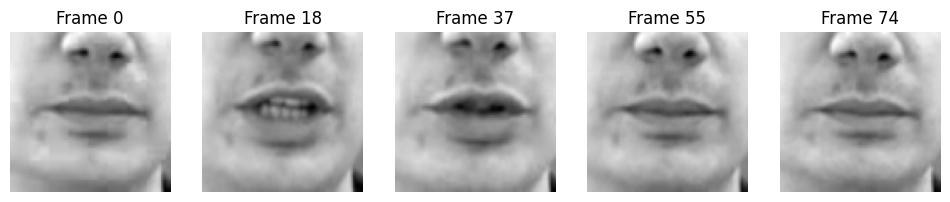

In [50]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = BASE_DIR + "/dataset/processed/speaker_1"

npy_files = glob.glob(
    OUTPUT_DIR + "/*.npy"
)

print("Total NPY files:", len(npy_files))
print("Dataset records:", len(dataset_df))

sample = np.load(npy_files[0])

print("Shape:", sample.shape)
print("Data type:", sample.dtype)
print("Minimum:", sample.min())
print("Maximum:", sample.max())
print("Contains NaN:", np.isnan(sample).any())
print("Contains Inf:", np.isinf(sample).any())

plt.figure(figsize=(12, 4))

for i, idx in enumerate(
    np.linspace(0, len(sample)-1, 5, dtype=int)
):
    plt.subplot(1, 5, i+1)
    plt.imshow(sample[idx], cmap="gray")
    plt.title(f"Frame {idx}")
    plt.axis("off")

plt.show()

In [51]:
print(dataset_df[
    ["video_id", "transcript", "mouth_path"]
].head(10))

print("\nMissing transcripts:",
      dataset_df["transcript"].isna().sum())

print("Missing mouth paths:",
      dataset_df["mouth_path"].isna().sum())

print("Existing mouth files:",
      sum(os.path.exists(p) for p in dataset_df["mouth_path"]))

  video_id                  transcript  \
0   bbaf2n       bin blue at f two now   
1   bbaf3s    bin blue at f three soon   
2   bbaf4p   bin blue at f four please   
3   bbaf5a    bin blue at f five again   
4   bbal6n       bin blue at l six now   
5   bbal7s    bin blue at l seven soon   
6   bbal8p  bin blue at l eight please   
7   bbal9a    bin blue at l nine again   
8   bbas1s      bin blue at s one soon   
9   bbas2p    bin blue at s two please   

                                          mouth_path  
0  /content/drive/MyDrive/Lip_Reading_System/data...  
1  /content/drive/MyDrive/Lip_Reading_System/data...  
2  /content/drive/MyDrive/Lip_Reading_System/data...  
3  /content/drive/MyDrive/Lip_Reading_System/data...  
4  /content/drive/MyDrive/Lip_Reading_System/data...  
5  /content/drive/MyDrive/Lip_Reading_System/data...  
6  /content/drive/MyDrive/Lip_Reading_System/data...  
7  /content/drive/MyDrive/Lip_Reading_System/data...  
8  /content/drive/MyDrive/Lip_Reading_Syst

In [52]:
def minimum_ctc_frames(target):
    repeats = sum(
        target[i] == target[i-1]
        for i in range(1, len(target))
    )
    return len(target) + repeats


dataset_df["min_ctc_frames"] = dataset_df[
    "encoded_text"
].apply(minimum_ctc_frames)

dataset_df["video_frames"] = dataset_df[
    "mouth_path"
].apply(
    lambda p: np.load(p, mmap_mode="r").shape[0]
)

dataset_df["ctc_valid"] = (
    dataset_df["video_frames"] >=
    dataset_df["min_ctc_frames"]
)

print("CTC-valid samples:",
      dataset_df["ctc_valid"].sum())

print("CTC-invalid samples:",
      (~dataset_df["ctc_valid"]).sum())

CTC-valid samples: 1000
CTC-invalid samples: 0


In [53]:
dataset_df = dataset_df[
    dataset_df["ctc_valid"]
].reset_index(drop=True)

print("Final usable records:", len(dataset_df))

Final usable records: 1000


In [54]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split

class LipReadingDataset(Dataset):

    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        frames = np.load(row["mouth_path"])

        frames = torch.tensor(
            frames,
            dtype=torch.float32
        ).unsqueeze(1)

        target = torch.tensor(
            row["encoded_text"],
            dtype=torch.long
        )

        return frames, target


def collate_fn(batch):

    videos, targets = zip(*batch)

    frame_lengths = torch.tensor(
        [len(v) for v in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [len(t) for t in targets],
        dtype=torch.long
    )

    max_frames = max(frame_lengths).item()

    padded_videos = torch.zeros(
        len(videos),
        max_frames,
        1,
        96,
        96
    )

    for i, video in enumerate(videos):
        padded_videos[i, :len(video)] = video

    return (
        padded_videos,
        torch.cat(targets),
        frame_lengths,
        target_lengths
    )


full_dataset = LipReadingDataset(dataset_df)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=generator
)

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 800
Validation samples: 200


In [55]:
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

vocab_size = len(char_to_idx) + 1

model = LipReadingModel(
    vocab_size=vocab_size,
    hidden_size=256
).to(device)

criterion = nn.CTCLoss(
    blank=0,
    zero_infinity=True
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Device:", device)
print("Model ready!")
print("Classes:", vocab_size)

Device: cuda
Model ready!
Classes: 29


In [56]:
videos, targets, frame_lengths, target_lengths = next(
    iter(train_loader)
)

videos = videos.to(device)
targets = targets.to(device)

model.eval()

with torch.no_grad():

    logits = model(videos)

    log_probs = F.log_softmax(
        logits,
        dim=2
    ).transpose(0, 1)

    test_loss = criterion(
        log_probs,
        targets,
        frame_lengths,
        target_lengths
    )

print("Video shape:", videos.shape)
print("Output shape:", logits.shape)
print("Initial CTC loss:", test_loss.item())

Video shape: torch.Size([2, 75, 1, 96, 96])
Output shape: torch.Size([2, 75, 29])
Initial CTC loss: 8.375226974487305


In [57]:
def train_one_epoch():

    model.train()
    total_loss = 0

    for videos, targets, frame_lengths, target_lengths in train_loader:

        videos = videos.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        logits = model(videos)

        log_probs = F.log_softmax(
            logits,
            dim=2
        ).transpose(0, 1)

        loss = criterion(
            log_probs,
            targets,
            frame_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss!")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)


def validate():

    model.eval()
    total_loss = 0

    with torch.no_grad():

        for videos, targets, frame_lengths, target_lengths in val_loader:

            videos = videos.to(device)
            targets = targets.to(device)

            logits = model(videos)

            log_probs = F.log_softmax(
                logits,
                dim=2
            ).transpose(0, 1)

            loss = criterion(
                log_probs,
                targets,
                frame_lengths,
                target_lengths
            )

            total_loss += loss.item()

    return total_loss / len(val_loader)

In [58]:
import time

EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    start = time.time()

    train_loss = train_one_epoch()
    val_loss = validate()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    elapsed = time.time() - start

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f} "
        f"Time: {elapsed:.2f}s"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            BASE_DIR + "/models/best_lipreading_model.pth"
        )

print("\nTraining completed!")

Epoch [1/10] Train Loss: 2.7978 Validation Loss: 2.5807 Time: 41.46s
Epoch [2/10] Train Loss: 2.4858 Validation Loss: 2.3870 Time: 39.59s
Epoch [3/10] Train Loss: 2.2245 Validation Loss: 1.9940 Time: 35.12s
Epoch [4/10] Train Loss: 1.8857 Validation Loss: 1.7305 Time: 34.32s
Epoch [5/10] Train Loss: 1.6592 Validation Loss: 1.5795 Time: 34.64s
Epoch [6/10] Train Loss: 1.5395 Validation Loss: 1.4623 Time: 34.24s
Epoch [7/10] Train Loss: 1.4638 Validation Loss: 1.4296 Time: 34.42s
Epoch [8/10] Train Loss: 1.4132 Validation Loss: 1.3865 Time: 34.40s
Epoch [9/10] Train Loss: 1.3687 Validation Loss: 1.3432 Time: 34.28s
Epoch [10/10] Train Loss: 1.3601 Validation Loss: 1.3912 Time: 34.54s

Training completed!


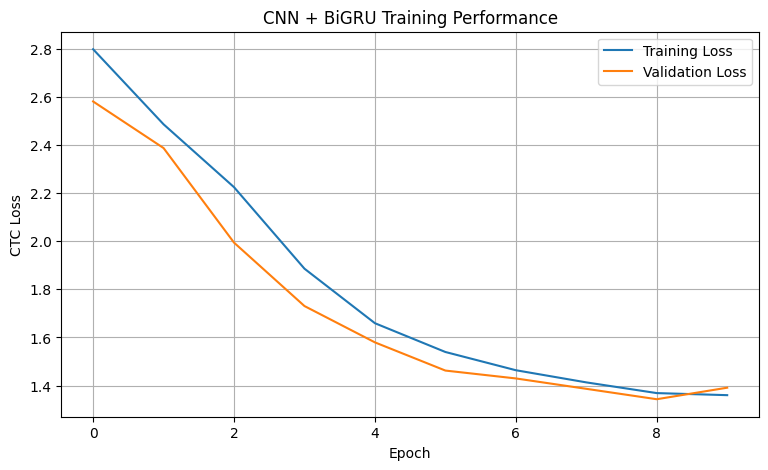

In [59]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.title("CNN + BiGRU Training Performance")

plt.legend()
plt.grid(True)
plt.show()

In [60]:
import pandas as pd

results = pd.DataFrame({
    "Epoch": range(1, EPOCHS + 1),
    "Training Loss": history["train_loss"],
    "Validation Loss": history["val_loss"]
})

results.to_csv(
    BASE_DIR + "/results/training_history.csv",
    index=False
)

print("Training history saved!")

Training history saved!


In [61]:
import os
import pandas as pd

HISTORY_PATH = (
    BASE_DIR + "/results/training_history.csv"
)

if os.path.exists(HISTORY_PATH):

    history_df = pd.read_csv(HISTORY_PATH)

    print(history_df.to_string(index=False))

else:
    print("Training history file not found.")

 Epoch  Training Loss  Validation Loss
     1       2.797784         2.580680
     2       2.485786         2.387022
     3       2.224455         1.994045
     4       1.885721         1.730454
     5       1.659159         1.579476
     6       1.539517         1.462330
     7       1.463761         1.429620
     8       1.413217         1.386476
     9       1.368716         1.343235
    10       1.360101         1.391163


In [62]:
def ctc_greedy_decode(log_probs, idx_to_char, blank=0):

    # Get the most probable character at each time step
    predictions = torch.argmax(
        log_probs,
        dim=-1
    )

    decoded_sentences = []

    for sequence in predictions:

        sentence = []
        previous = None

        for token in sequence.tolist():

            # Collapse consecutive repeated characters
            if token != previous and token != blank:

                if token in idx_to_char:
                    sentence.append(idx_to_char[token])

            previous = token

        decoded_sentences.append(
            "".join(sentence)
        )

    return decoded_sentences

In [63]:
idx_to_char = {
    idx: char
    for char, idx in char_to_idx.items()
}

print("Vocabulary ready!")
print("Blank token:", 0)
print("Number of characters:", len(idx_to_char))

Vocabulary ready!
Blank token: 0
Number of characters: 28


In [64]:
import torch

MODEL_PATH = (
    BASE_DIR + "/models/best_lipreading_model.pth"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Trained model checkpoint not found. "
        "Complete model training first."
    )

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

# Your earlier training code saved state_dict directly.
model.load_state_dict(checkpoint)

model.eval()

print("Trained model loaded successfully!")

Trained model loaded successfully!


In [65]:
def predict_batch(videos):

    model.eval()

    videos = videos.to(device)

    with torch.no_grad():

        logits = model(videos)

        log_probs = F.log_softmax(
            logits,
            dim=2
        )

        predictions = ctc_greedy_decode(
            log_probs,
            idx_to_char,
            blank=0
        )

    return predictions

In [66]:
videos, targets, frame_lengths, target_lengths = next(
    iter(val_loader)
)

predictions = predict_batch(videos)

print("MODEL PREDICTIONS:\n")

for i, prediction in enumerate(predictions):

    print(f"Video {i+1}")
    print("Predicted:", prediction)
    print("-" * 40)

MODEL PREDICTIONS:

Video 1
Predicted: bat wree it sine noon
----------------------------------------
Video 2
Predicted: bat wree it sine noaon
----------------------------------------


In [67]:
def decode_reference(targets, target_lengths):

    references = []
    position = 0

    for length in target_lengths.tolist():

        sequence = targets[
            position:position + length
        ]

        sentence = "".join(
            idx_to_char[int(token)]
            for token in sequence
        )

        references.append(sentence)

        position += length

    return references


references = decode_reference(
    targets,
    target_lengths
)

for i in range(len(predictions)):

    print("Actual:   ", references[i])
    print("Predicted:", predictions[i])
    print()

Actual:    place red with q three soon
Predicted: bat wree it sine noon

Actual:    set green in c one again
Predicted: bat wree it sine noaon



In [68]:
!pip install -q jiwer

In [69]:
from jiwer import wer, cer

word_error = wer(
    references,
    predictions
)

character_error = cer(
    references,
    predictions
)

print("Word Error Rate (WER):", word_error)
print("Character Error Rate (CER):", character_error)

print("WER percentage:", word_error * 100, "%")
print("CER percentage:", character_error * 100, "%")

Word Error Rate (WER): 1.0
Character Error Rate (CER): 0.5098039215686274
WER percentage: 100.0 %
CER percentage: 50.98039215686274 %


In [70]:
from jiwer import wer, cer

all_references = []
all_predictions = []

model.eval()

with torch.no_grad():

    for videos, targets, frame_lengths, target_lengths in val_loader:

        videos = videos.to(device)

        logits = model(videos)

        log_probs = F.log_softmax(
            logits,
            dim=2
        )

        batch_predictions = ctc_greedy_decode(
            log_probs,
            idx_to_char,
            blank=0
        )

        batch_references = decode_reference(
            targets,
            target_lengths
        )

        all_predictions.extend(batch_predictions)
        all_references.extend(batch_references)


final_wer = wer(
    all_references,
    all_predictions
)

final_cer = cer(
    all_references,
    all_predictions
)

print("Total validation samples:", len(all_references))

print("Final WER:", round(final_wer, 4))
print("Final CER:", round(final_cer, 4))

print("WER percentage:", round(final_wer * 100, 2), "%")
print("CER percentage:", round(final_cer * 100, 2), "%")

Total validation samples: 200
Final WER: 1.0
Final CER: 0.5773
WER percentage: 100.0 %
CER percentage: 57.73 %


In [71]:
evaluation_df = pd.DataFrame({
    "Actual Sentence": all_references,
    "Predicted Sentence": all_predictions
})

evaluation_path = (
    BASE_DIR + "/results/predictions.csv"
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

metrics_df = pd.DataFrame({
    "Metric": ["WER", "CER"],
    "Value": [final_wer, final_cer],
    "Percentage": [
        final_wer * 100,
        final_cer * 100
    ]
})

metrics_df.to_csv(
    BASE_DIR + "/results/evaluation_metrics.csv",
    index=False
)

print("Predictions saved!")
print("Evaluation metrics saved!")

Predictions saved!
Evaluation metrics saved!


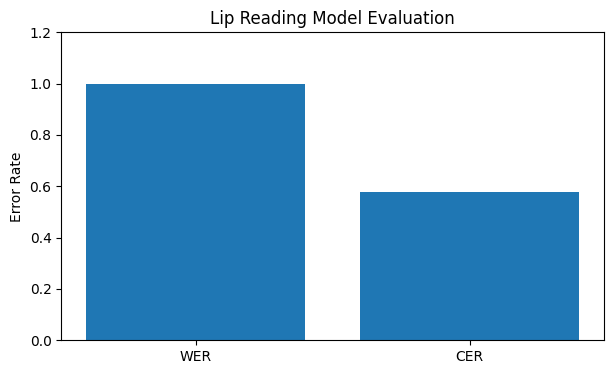

In [72]:
import matplotlib.pyplot as plt

metrics = {
    "WER": final_wer,
    "CER": final_cer
}

plt.figure(figsize=(7, 4))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylabel("Error Rate")
plt.title("Lip Reading Model Evaluation")
plt.ylim(0, max(1, max(metrics.values()) * 1.2))

plt.show()

In [73]:
import os
import pandas as pd

print("Train dataframe:", "train_df" in globals())
print("Validation dataframe:", "val_df" in globals())
print("Character vocabulary:", "char_to_idx" in globals())
print("Trained model:", "model" in globals())
print("Device:", device if "device" in globals() else "Not defined")

print("\nTraining dataframe columns:")
if "train_df" in globals():
    print(train_df.columns.tolist())
    display(train_df.head(3))

print("\nValidation dataframe columns:")
if "val_df" in globals():
    print(val_df.columns.tolist())
    display(val_df.head(3))

# Check saved training history
history_path = BASE_DIR + "/results/training_history.csv"
print("\nTraining history exists:", os.path.exists(history_path))

if os.path.exists(history_path):
    history = pd.read_csv(history_path)
    display(history.tail())

Train dataframe: False
Validation dataframe: False
Character vocabulary: True
Trained model: True
Device: cuda

Training dataframe columns:

Validation dataframe columns:

Training history exists: True


,Epoch,Training Loss,Validation Loss
5,6,1.539517,1.462330
6,7,1.463761,1.429620
7,8,1.413217,1.386476
8,9,1.368716,1.343235
9,10,1.360101,1.391163


In [74]:
import os

print("BASE_DIR:", BASE_DIR)

for folder in [
    BASE_DIR,
    BASE_DIR + "/dataset",
    BASE_DIR + "/dataset/raw",
    BASE_DIR + "/dataset/transcripts",
    BASE_DIR + "/dataset/processed",
    BASE_DIR + "/results",
    BASE_DIR + "/models"
]:
    print("\nFolder:", folder)

    if os.path.exists(folder):
        print(os.listdir(folder)[:15])
    else:
        print("Folder not found")

BASE_DIR: /content/drive/MyDrive/Lip_Reading_System

Folder: /content/drive/MyDrive/Lip_Reading_System
['dataset', 'models', 'results', 'notebooks']

Folder: /content/drive/MyDrive/Lip_Reading_System/dataset
['raw', 'processed', 'transcripts']

Folder: /content/drive/MyDrive/Lip_Reading_System/dataset/raw
['s1.mpg_vcd.zip', 's1']

Folder: /content/drive/MyDrive/Lip_Reading_System/dataset/transcripts
['s1.tar', 'align', 'grid_transcripts.csv', 'vocabulary.json']

Folder: /content/drive/MyDrive/Lip_Reading_System/dataset/processed
['speaker_1']

Folder: /content/drive/MyDrive/Lip_Reading_System/results
['training_history.csv', 'predictions.csv', 'evaluation_metrics.csv']

Folder: /content/drive/MyDrive/Lip_Reading_System/models
['lipreading_cnn_bigru.pth', 'best_lipreading_model.pth']


In [75]:
import glob

align_files = glob.glob(
    BASE_DIR + "/dataset/raw/**/*.align",
    recursive=True
)

print("Alignment files found:", len(align_files))

if align_files:
    print("\nSample alignment file:", align_files[0])

    with open(align_files[0], "r", encoding="utf-8") as f:
        print(f.read()[:1000])

Alignment files found: 0


In [76]:
import os
import pandas as pd
import json
import glob

TRANSCRIPT_DIR = BASE_DIR + "/dataset/transcripts"

# 1. Inspect saved transcript CSV
csv_path = TRANSCRIPT_DIR + "/grid_transcripts.csv"

print("CSV exists:", os.path.exists(csv_path))

if os.path.exists(csv_path):
    transcripts_df = pd.read_csv(csv_path)

    print("\nCSV columns:")
    print(transcripts_df.columns.tolist())

    print("\nNumber of transcript records:", len(transcripts_df))
    display(transcripts_df.head())

# 2. Inspect vocabulary
vocab_path = TRANSCRIPT_DIR + "/vocabulary.json"

print("\nVocabulary exists:", os.path.exists(vocab_path))

if os.path.exists(vocab_path):
    with open(vocab_path, "r") as f:
        saved_vocab = json.load(f)

    print("Vocabulary sample:")
    print(list(saved_vocab.items())[:15])

# 3. Find alignment files in the correct folder
align_files = glob.glob(
    TRANSCRIPT_DIR + "/align/**/*.align",
    recursive=True
)

print("\nAlignment files found:", len(align_files))

if align_files:
    print("Sample alignment:", align_files[0])

CSV exists: True

CSV columns:
['video_id', 'video_path', 'align_path', 'transcript']

Number of transcript records: 1000


,video_id,video_path,align_path,transcript
0,bbaf2n,/content/drive/MyDrive/Lip_Reading_System/data...,/content/drive/MyDrive/Lip_Reading_System/data...,bin blue at f two now
1,bbaf3s,/content/drive/MyDrive/Lip_Reading_System/data...,/content/drive/MyDrive/Lip_Reading_System/data...,bin blue at f three soon
2,bbaf4p,/content/drive/MyDrive/Lip_Reading_System/data...,/content/drive/MyDrive/Lip_Reading_System/data...,bin blue at f four please
3,bbaf5a,/content/drive/MyDrive/Lip_Reading_System/data...,/content/drive/MyDrive/Lip_Reading_System/data...,bin blue at f five again
4,bbal6n,/content/drive/MyDrive/Lip_Reading_System/data...,/content/drive/MyDrive/Lip_Reading_System/data...,bin blue at l six now



Vocabulary exists: True
Vocabulary sample:
[('char_to_idx', {'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, ' ': 27, "'": 28}), ('blank_index', 0)]

Alignment files found: 1000
Sample alignment: /content/drive/MyDrive/Lip_Reading_System/dataset/transcripts/align/bbaf2n.align


In [77]:
import os
import pandas as pd
import numpy as np

# Load saved transcript records
csv_path = BASE_DIR + "/dataset/transcripts/grid_transcripts.csv"
transcripts_df = pd.read_csv(csv_path)

# Locate processed mouth sequences
PROCESSED_DIR = BASE_DIR + "/dataset/processed/speaker_1"

transcripts_df["mouth_path"] = transcripts_df["video_id"].apply(
    lambda x: os.path.join(PROCESSED_DIR, str(x) + ".npy")
)

# Keep records whose processed mouth sequence exists
transcripts_df["file_exists"] = transcripts_df["mouth_path"].apply(
    os.path.exists
)

print("Total transcript records:", len(transcripts_df))
print("Processed mouth files found:", transcripts_df["file_exists"].sum())
print("Missing mouth files:", (~transcripts_df["file_exists"]).sum())

# Inspect saved Step 6 predictions
predictions_path = BASE_DIR + "/results/predictions.csv"

print("\nPredictions file exists:", os.path.exists(predictions_path))

if os.path.exists(predictions_path):
    predictions_df = pd.read_csv(predictions_path)
    print("Prediction columns:", predictions_df.columns.tolist())
    print("Prediction records:", len(predictions_df))
    display(predictions_df.head())

# Inspect evaluation metrics
metrics_path = BASE_DIR + "/results/evaluation_metrics.csv"

if os.path.exists(metrics_path):
    print("\nSaved evaluation metrics:")
    display(pd.read_csv(metrics_path))

Total transcript records: 1000
Processed mouth files found: 1000
Missing mouth files: 0

Predictions file exists: True
Prediction columns: ['Actual Sentence', 'Predicted Sentence']
Prediction records: 200


,Actual Sentence,Predicted Sentence
0,place red with q three soon,bat wree it sine noon
1,set green in c one again,bat wree it sine noaon
2,set blue at a six please,sat wree it sine noon
3,place green by y six please,sat wree it sine noon
4,place white in j three soon,bat wree it sine noon



Saved evaluation metrics:


,Metric,Value,Percentage
0,WER,1.000000,100.000000
1,CER,0.577295,57.729469


In [78]:
import re
import pandas as pd

def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower().strip())

# Normalize transcript text
transcripts_df["normalized_transcript"] = (
    transcripts_df["transcript"].apply(normalize_text)
)

predictions_df["normalized_actual"] = (
    predictions_df["Actual Sentence"].apply(normalize_text)
)

# Check whether validation sentences match transcript records
sentence_counts = transcripts_df["normalized_transcript"].value_counts()

print("Unique transcript sentences:", sentence_counts.nunique())
print("Duplicate transcript sentences:",
      (sentence_counts > 1).sum())

matched_ids = set(
    transcripts_df.loc[
        transcripts_df["normalized_transcript"].isin(
            predictions_df["normalized_actual"]
        ),
        "video_id"
    ].astype(str)
)

unmatched_sentences = set(predictions_df["normalized_actual"]) - set(
    transcripts_df["normalized_transcript"]
)

print("\nValidation prediction rows:", len(predictions_df))
print("Matched validation video IDs:", len(matched_ids))
print("Unmatched actual sentences:", len(unmatched_sentences))

# Show unmatched sentences, if any
print("\nUnmatched examples:", list(unmatched_sentences)[:10])

Unique transcript sentences: 1
Duplicate transcript sentences: 0

Validation prediction rows: 200
Matched validation video IDs: 200
Unmatched actual sentences: 0

Unmatched examples: []


In [79]:
validation_df = transcripts_df[
    transcripts_df["video_id"].astype(str).isin(matched_ids)
].copy()

train_df = transcripts_df[
    ~transcripts_df["video_id"].astype(str).isin(matched_ids)
].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))

print("\nTraining transcript examples:")
display(train_df[["video_id", "transcript"]].head())

print("\nValidation transcript examples:")
display(validation_df[["video_id", "transcript"]].head())

assert len(train_df) + len(validation_df) == len(transcripts_df)

Training samples: 800
Validation samples: 200

Training transcript examples:


,video_id,transcript
0,bbaf2n,bin blue at f two now
3,bbaf5a,bin blue at f five again
4,bbal6n,bin blue at l six now
5,bbal7s,bin blue at l seven soon
6,bbal8p,bin blue at l eight please



Validation transcript examples:


,video_id,transcript
1,bbaf3s,bin blue at f three soon
2,bbaf4p,bin blue at f four please
7,bbal9a,bin blue at l nine again
13,bbaz5s,bin blue at z five soon
14,bbaz6p,bin blue at z six please


In [80]:
# Install NLTK if needed
!pip -q install nltk

from nltk.lm import Laplace
from nltk.lm.preprocessing import padded_everygram_pipeline
import numpy as np
import re

# Prepare training sentences as word tokens
train_sentences = [
    str(sentence).lower().split()
    for sentence in train_df["transcript"]
]

# Build bigram language model
bigram_order = 2
bigram_train, bigram_vocab = padded_everygram_pipeline(
    bigram_order, train_sentences
)

bigram_lm = Laplace(bigram_order)
bigram_lm.fit(bigram_train, bigram_vocab)

# Build trigram language model
trigram_order = 3
trigram_train, trigram_vocab = padded_everygram_pipeline(
    trigram_order, train_sentences
)

trigram_lm = Laplace(trigram_order)
trigram_lm.fit(trigram_train, trigram_vocab)

print("Bigram language model trained!")
print("Trigram language model trained!")
print("Training sentences:", len(train_sentences))

Bigram language model trained!
Trigram language model trained!
Training sentences: 800


In [81]:
import math

def language_model_score(sentence, lm, order):
    words = str(sentence).lower().split()

    # Add sentence boundary tokens
    tokens = ["<s>"] * (order - 1) + words + ["</s>"]

    total_score = 0.0

    for i in range(order - 1, len(tokens)):
        word = tokens[i]
        context = tokens[i - order + 1:i]

        probability = lm.score(word, context)
        total_score += math.log(max(probability, 1e-12))

    return total_score


test_sentence = "place red with q three soon"

print("Test sentence:", test_sentence)
print("Bigram score:",
      language_model_score(test_sentence, bigram_lm, 2))
print("Trigram score:",
      language_model_score(test_sentence, trigram_lm, 3))

Test sentence: place red with q three soon
Bigram score: -13.73021830059908
Trigram score: -16.96474981721491


In [83]:
import os
import pickle

MODEL_DIR = BASE_DIR + "/models"
os.makedirs(MODEL_DIR, exist_ok=True)

lm_path = MODEL_DIR + "/ngram_language_models.pkl"

with open(lm_path, "wb") as f:
    pickle.dump({
        "bigram_lm": bigram_lm,
        "trigram_lm": trigram_lm
    }, f)

print("Language models saved successfully!")
print("Saved at:", lm_path)

Language models saved successfully!
Saved at: /content/drive/MyDrive/Lip_Reading_System/models/ngram_language_models.pkl


In [84]:
import torch
import numpy as np

model.eval()

# Take one validation example
sample_row = validation_df.iloc[0]

mouth_path = sample_row["mouth_path"]
frames = np.load(mouth_path)

print("Video ID:", sample_row["video_id"])
print("Actual transcript:", sample_row["transcript"])
print("Mouth sequence shape:", frames.shape)

# Convert to model input: [1, T, 1, 96, 96]
video_tensor = torch.tensor(
    frames,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(2).to(device)

with torch.no_grad():
    logits = model(video_tensor)
    log_probs = torch.nn.functional.log_softmax(logits, dim=-1)

print("Model output shape:", tuple(logits.shape))
print("Log probability shape:", tuple(log_probs.shape))
print("Vocabulary size:", len(char_to_idx) + 1)

Video ID: bbaf3s
Actual transcript: bin blue at f three soon
Mouth sequence shape: (75, 96, 96)
Model output shape: (1, 75, 29)
Log probability shape: (1, 75, 29)
Vocabulary size: 29


In [85]:
import numpy as np
import math

# Ensure character mappings are correct
idx_to_char = {
    int(idx): char
    for char, idx in char_to_idx.items()
}

BLANK = 0

def get_trigram_increment(prefix, new_char, lm, alpha):
    """
    Add trigram language-model score when a word is completed.
    """
    if new_char != " ":
        return 0.0

    words = prefix.strip().split()

    if not words:
        return 0.0

    completed_word = words[-1]

    context_words = ["<s>", "<s>"] + words[:-1]
    context = context_words[-2:]

    probability = lm.score(completed_word, context)

    return alpha * math.log(max(probability, 1e-12))


def ctc_prefix_beam_search(
    log_probs,
    idx_to_char,
    lm,
    beam_width=25,
    alpha=0.3
):
    """
    Approximate CTC prefix beam search with trigram language scoring.

    log_probs shape: [time_steps, vocabulary_size]
    """

    # Each prefix stores (blank_score, nonblank_score)
    beams = {
        "": (0.0, -np.inf)
    }

    def log_add(a, b):
        return np.logaddexp(a, b)

    for t in range(log_probs.shape[0]):

        next_beams = {}

        def update(prefix, blank_score=None, nonblank_score=None):

            old_blank, old_nonblank = next_beams.get(
                prefix, (-np.inf, -np.inf)
            )

            if blank_score is not None:
                old_blank = log_add(old_blank, blank_score)

            if nonblank_score is not None:
                old_nonblank = log_add(old_nonblank, nonblank_score)

            next_beams[prefix] = (old_blank, old_nonblank)

        for prefix, (pb, pnb) in beams.items():

            total_score = log_add(pb, pnb)

            # 1. Extend with blank
            blank_score = total_score + log_probs[t, BLANK]
            update(prefix, blank_score=blank_score)

            # 2. Extend with nonblank characters
            for token_id in range(log_probs.shape[1]):

                if token_id == BLANK:
                    continue

                char = idx_to_char.get(token_id)

                if char is None:
                    continue

                # Avoid unnecessary leading or repeated spaces
                if char == " " and (
                    not prefix or prefix.endswith(" ")
                ):
                    continue

                char_score = log_probs[t, token_id]

                if prefix and char == prefix[-1]:

                    # Repeated character without an intervening blank:
                    # CTC collapses it to the existing prefix.
                    update(
                        prefix,
                        nonblank_score=pnb + char_score
                    )

                    # Repeated character after a blank:
                    # this creates a new character.
                    new_prefix = prefix + char

                    lm_score = get_trigram_increment(
                        prefix, char, lm, alpha
                    )

                    update(
                        new_prefix,
                        nonblank_score=(
                            pb + char_score + lm_score
                        )
                    )

                else:

                    new_prefix = prefix + char

                    lm_score = get_trigram_increment(
                        prefix, char, lm, alpha
                    )

                    update(
                        new_prefix,
                        nonblank_score=(
                            total_score + char_score + lm_score
                        )
                    )

        # Keep only the highest-scoring prefixes
        beams = dict(
            sorted(
                next_beams.items(),
                key=lambda item: log_add(
                    item[1][0], item[1][1]
                ),
                reverse=True
            )[:beam_width]
        )

    # Add the end-of-sentence language-model score
    candidates = []

    for prefix, (pb, pnb) in beams.items():

        words = prefix.strip().split()

        if not words:
            continue

        context = (["<s>", "<s>"] + words)[-2:]

        end_probability = lm.score("</s>", context)

        final_score = (
            log_add(pb, pnb)
            + alpha * math.log(max(end_probability, 1e-12))
        )

        candidates.append((prefix.strip(), final_score))

    return sorted(
        candidates,
        key=lambda item: item[1],
        reverse=True
    )

In [86]:
import torch
import torch.nn.functional as F
import numpy as np

model.eval()

sample_row = validation_df.iloc[0]

frames = np.load(sample_row["mouth_path"])

video_tensor = torch.tensor(
    frames,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(2).to(device)

with torch.no_grad():
    logits = model(video_tensor)

    log_probs = F.log_softmax(
        logits, dim=-1
    )[0].cpu().numpy()

# Original greedy prediction
def greedy_decode(log_probs, idx_to_char, blank=0):
    token_ids = np.argmax(log_probs, axis=-1)

    result = []
    previous = None

    for token in token_ids:
        if token != previous and token != blank:
            if token in idx_to_char:
                result.append(idx_to_char[token])

        previous = token

    return "".join(result).strip()


greedy_text = greedy_decode(
    log_probs,
    idx_to_char
)

# Trigram-assisted beam search
candidates = ctc_prefix_beam_search(
    log_probs=log_probs,
    idx_to_char=idx_to_char,
    lm=trigram_lm,
    beam_width=25,
    alpha=0.3
)

print("Video ID:", sample_row["video_id"])
print("Actual:", sample_row["transcript"])
print("Greedy prediction:", greedy_text)

print("\nTop 5 beam-search candidates:")

for i, (sentence, score) in enumerate(candidates[:5], 1):
    print(f"{i}. {sentence} | Score: {score:.3f}")

Video ID: bbaf3s
Actual: bin blue at f three soon
Greedy prediction: bat wree it sine noon

Top 5 beam-search candidates:
1. bate wree ith m tsie pnoon | Score: -43.678
2. bate wree ith m tsie pnoaon | Score: -43.694
3. bate wree ith m tsine pnoon | Score: -43.734
4. bate wree ith m tse pnoon | Score: -43.769
5. sate wree ith m tsine pnoon | Score: -43.771


In [87]:
!pip -q install jiwer tqdm

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from jiwer import wer, cer

model.eval()

references = []
greedy_predictions = []
beam_predictions = []

BEAM_WIDTH = 25
LM_ALPHA = 0.3

for _, row in tqdm(validation_df.iterrows(), total=len(validation_df)):

    frames = np.load(row["mouth_path"])

    video_tensor = torch.tensor(
        frames,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(2).to(device)

    with torch.no_grad():
        logits = model(video_tensor)
        log_probs = F.log_softmax(
            logits, dim=-1
        )[0].cpu().numpy()

    # Greedy decoding
    greedy_text = greedy_decode(log_probs, idx_to_char)

    # Trigram-assisted beam search
    candidates = ctc_prefix_beam_search(
        log_probs=log_probs,
        idx_to_char=idx_to_char,
        lm=trigram_lm,
        beam_width=BEAM_WIDTH,
        alpha=LM_ALPHA
    )

    beam_text = candidates[0][0] if candidates else ""

    references.append(normalize_text(row["transcript"]))
    greedy_predictions.append(normalize_text(greedy_text))
    beam_predictions.append(normalize_text(beam_text))


# Calculate metrics
greedy_wer = wer(references, greedy_predictions)
greedy_cer = cer(references, greedy_predictions)

beam_wer = wer(references, beam_predictions)
beam_cer = cer(references, beam_predictions)

print("VALIDATION RESULTS")
print("------------------------------")
print(f"Greedy WER: {greedy_wer:.4f} ({greedy_wer*100:.2f}%)")
print(f"Greedy CER: {greedy_cer:.4f} ({greedy_cer*100:.2f}%)")

print("\nTRIGRAM BEAM SEARCH RESULTS")
print("------------------------------")
print(f"Beam WER: {beam_wer:.4f} ({beam_wer*100:.2f}%)")
print(f"Beam CER: {beam_cer:.4f} ({beam_cer*100:.2f}%)")


# Save comparison
comparison_df = pd.DataFrame({
    "Actual": references,
    "Greedy Prediction": greedy_predictions,
    "Beam Prediction": beam_predictions
})

comparison_path = BASE_DIR + "/results/step7_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

metrics_df = pd.DataFrame({
    "Method": ["Greedy CTC", "Trigram CTC Beam Search"],
    "WER": [greedy_wer, beam_wer],
    "CER": [greedy_cer, beam_cer]
})

metrics_path = BASE_DIR + "/results/step7_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\nComparison saved:", comparison_path)
print("Metrics saved:", metrics_path)

display(metrics_df)
display(comparison_df.head(10))

  0%|          | 0/200 [00:00<?, ?it/s]

VALIDATION RESULTS
------------------------------
Greedy WER: 1.0000 (100.00%)
Greedy CER: 0.5771 (57.71%)

TRIGRAM BEAM SEARCH RESULTS
------------------------------
Beam WER: 1.0000 (100.00%)
Beam CER: 0.6361 (63.61%)

Comparison saved: /content/drive/MyDrive/Lip_Reading_System/results/step7_comparison.csv
Metrics saved: /content/drive/MyDrive/Lip_Reading_System/results/step7_metrics.csv


,Method,WER,CER
0,Greedy CTC,1.0,0.577093
1,Trigram CTC Beam Search,1.0,0.636071


,Actual,Greedy Prediction,Beam Prediction
0,bin blue at f three soon,bat wree it sine noon,bate wree ith m tsie pnoon
1,bin blue at f four please,sat wree it sine noon,sate wree ith m tsie pnoon
2,bin blue at l nine again,sat wree it sine noaon,sate wree it hm tsine pnoon
3,bin blue at z five soon,bat wree it sine noaon,bate wree it hm tsine pnoon
4,bin blue at z six please,bat wree it sine noon,bate wree it hm tsine pnoon
5,bin blue by f nine again,bat wree it sine noon,bate wree it hm tsine pnoon
6,bin blue in f one again,bat wree it sine noon,bate wree ith m tsine pnoon
7,bin blue in z zero now,bat wree it sine noaon,bate wree ith m tsine pnoaon
8,bin blue with s nine soon,sat wree it sine noon,sate wree it hm tsine pnoon
9,bin green at a nine again,bat wrie it sine noon,bate wrie it hm tsine pnoon


In [88]:
from collections import Counter

print("Unique greedy predictions:",
      comparison_df["Greedy Prediction"].nunique())

print("Unique beam predictions:",
      comparison_df["Beam Prediction"].nunique())

print("\nMost common greedy predictions:")
for sentence, count in Counter(
    comparison_df["Greedy Prediction"]
).most_common(10):
    print(count, ":", sentence)

print("\nMost common actual sentences:")
for sentence, count in Counter(
    comparison_df["Actual"]
).most_common(10):
    print(count, ":", sentence)

print("\nAverage sentence lengths:")
print("Actual:",
      comparison_df["Actual"].str.split().str.len().mean())

print("Greedy:",
      comparison_df["Greedy Prediction"].str.split().str.len().mean())

Unique greedy predictions: 6
Unique beam predictions: 15

Most common greedy predictions:
112 : sat wree it sine noon
50 : bat wree it sine noon
26 : sat wree it sine noaon
10 : bat wree it sine noaon
1 : bat wrie it sine noon
1 : plan re it sine noaon

Most common actual sentences:
1 : bin blue at f three soon
1 : bin blue at f four please
1 : bin blue at l nine again
1 : bin blue at z five soon
1 : bin blue at z six please
1 : bin blue by f nine again
1 : bin blue in f one again
1 : bin blue in z zero now
1 : bin blue with s nine soon
1 : bin green at a nine again

Average sentence lengths:
Actual: 6.0
Greedy: 5.0



Video: bbaf3s
Transcript: bin blue at f three soon
Shape: (75, 96, 96)
Min: 0.14117648
Max: 0.8117647
Mean: 0.5456444
Standard deviation: 0.08601492
All finite: True

Video: bbaf4p
Transcript: bin blue at f four please
Shape: (75, 96, 96)
Min: 0.09803922
Max: 0.79607844
Mean: 0.53855354
Standard deviation: 0.09214628
All finite: True

Video: bbal9a
Transcript: bin blue at l nine again
Shape: (75, 96, 96)
Min: 0.12941177
Max: 0.8156863
Mean: 0.55444324
Standard deviation: 0.08570054
All finite: True

Video: bbaz5s
Transcript: bin blue at z five soon
Shape: (75, 96, 96)
Min: 0.105882354
Max: 0.8392157
Mean: 0.5593287
Standard deviation: 0.08964211
All finite: True


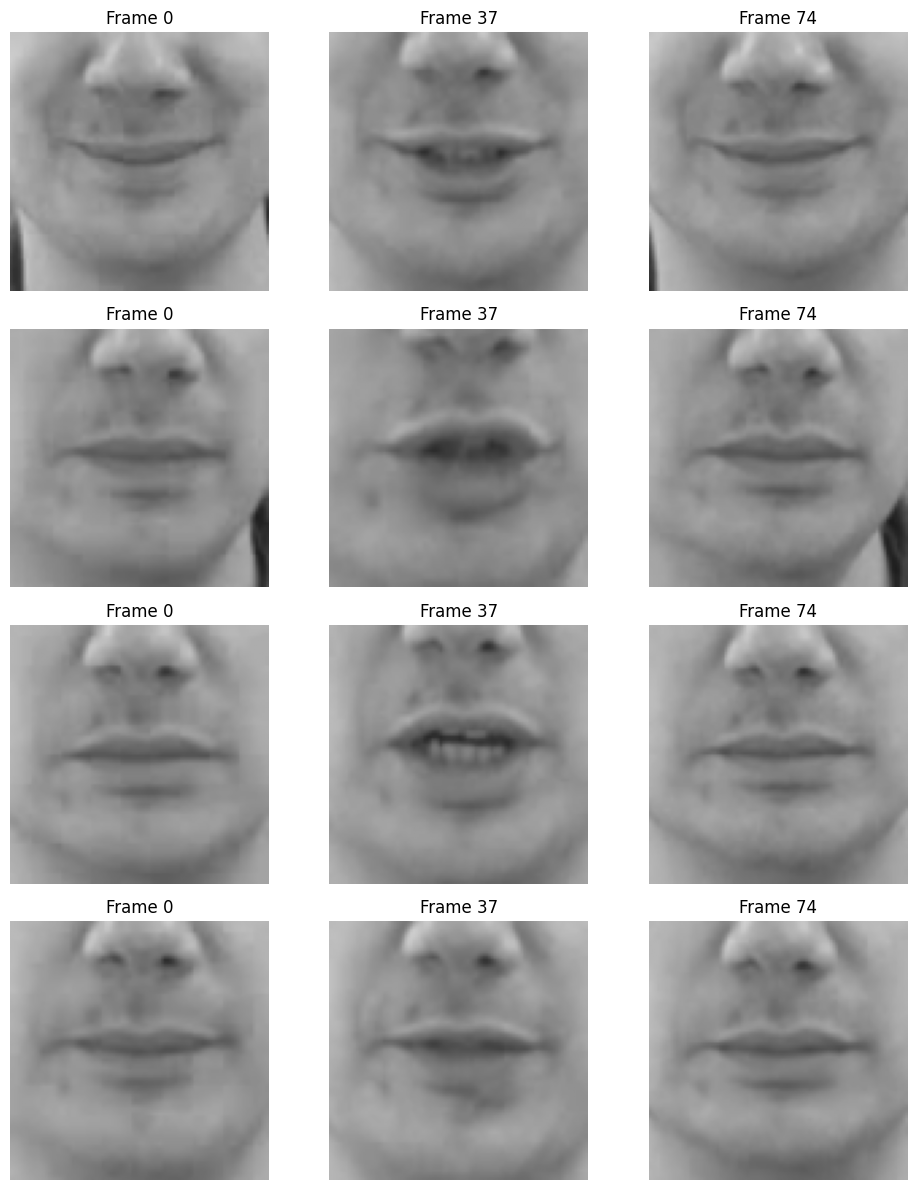

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import os

sample_count = min(4, len(validation_df))
sample_rows = validation_df.iloc[:sample_count]

fig, axes = plt.subplots(
    sample_count, 3,
    figsize=(10, 3 * sample_count)
)

if sample_count == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (_, row) in enumerate(sample_rows.iterrows()):

    frames = np.load(row["mouth_path"])

    # Select early, middle and late frames
    frame_indices = [
        0,
        len(frames) // 2,
        len(frames) - 1
    ]

    print("\nVideo:", row["video_id"])
    print("Transcript:", row["transcript"])
    print("Shape:", frames.shape)
    print("Min:", frames.min())
    print("Max:", frames.max())
    print("Mean:", frames.mean())
    print("Standard deviation:", frames.std())
    print("All finite:", np.isfinite(frames).all())

    for j, frame_idx in enumerate(frame_indices):

        axes[i, j].imshow(
            frames[frame_idx],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].set_title(
            f"Frame {frame_idx}"
        )

        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

diagnostics = []

for _, row in validation_df.head(10).iterrows():

    frames = np.load(row["mouth_path"])

    # Average difference between consecutive frames
    frame_differences = np.abs(
        frames[1:] - frames[:-1]
    )

    diagnostics.append({
        "video_id": row["video_id"],
        "transcript": row["transcript"],
        "temporal_difference": frame_differences.mean(),
        "temporal_std": frames.std(axis=0).mean(),
        "unique_frames": len(np.unique(
            frames.reshape(len(frames), -1), axis=0
        ))
    })

diagnostics_df = pd.DataFrame(diagnostics)

display(diagnostics_df)

print("\nAverage temporal difference:",
      diagnostics_df["temporal_difference"].mean())

print("Average unique frames:",
      diagnostics_df["unique_frames"].mean())

,video_id,transcript,temporal_difference,temporal_std,unique_frames
0,bbaf3s,bin blue at f three soon,0.011331,0.029356,75
1,bbaf4p,bin blue at f four please,0.013410,0.030526,75
2,bbal9a,bin blue at l nine again,0.014254,0.030804,75
3,bbaz5s,bin blue at z five soon,0.015398,0.031647,75
4,bbaz6p,bin blue at z six please,0.011546,0.029191,75
5,bbbf9a,bin blue by f nine again,0.011861,0.028834,75
6,bbif1a,bin blue in f one again,0.012596,0.033610,75
7,bbizzn,bin blue in z zero now,0.014529,0.031269,63
8,bbws9s,bin blue with s nine soon,0.013415,0.030170,75
9,bgaa9a,bin green at a nine again,0.012932,0.029621,75



Average temporal difference: 0.013127094
Average unique frames: 73.8


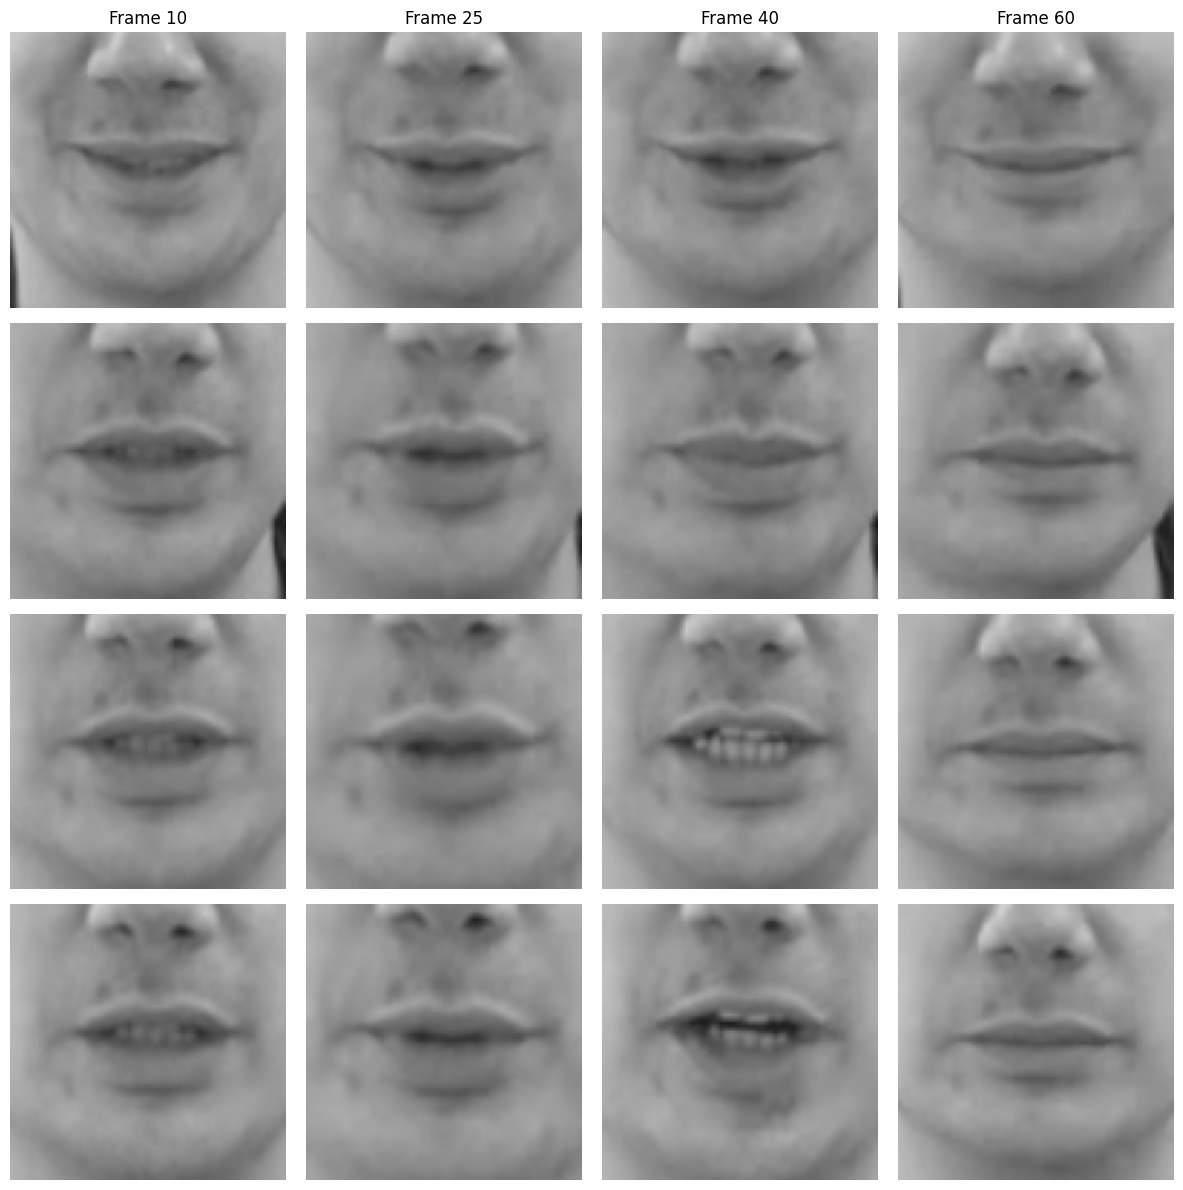

In [91]:
import matplotlib.pyplot as plt
import numpy as np

sample_rows = validation_df.iloc[:4]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, (_, row) in enumerate(sample_rows.iterrows()):

    frames = np.load(row["mouth_path"])

    for j, frame_idx in enumerate([
        10, 25, 40, 60
    ]):

        axes[i, j].imshow(
            frames[frame_idx],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].axis("off")

        if i == 0:
            axes[i, j].set_title(
                f"Frame {frame_idx}"
            )

    axes[i, 0].set_ylabel(
        str(row["video_id"]),
        rotation=0,
        labelpad=35
    )

plt.tight_layout()
plt.show()

In [92]:
import numpy as np
import pandas as pd

diagnostics = []

for _, row in validation_df.head(10).iterrows():

    frames = np.load(row["mouth_path"])

    differences = np.abs(frames[1:] - frames[:-1])

    diagnostics.append({
        "video_id": row["video_id"],
        "transcript": row["transcript"],
        "temporal_difference": float(differences.mean()),
        "temporal_std": float(frames.std(axis=0).mean()),
        "unique_frames": len(
            np.unique(frames.reshape(len(frames), -1), axis=0)
        )
    })

diagnostics_df = pd.DataFrame(diagnostics)

display(diagnostics_df)

print("Average temporal difference:",
      diagnostics_df["temporal_difference"].mean())

print("Average unique frames:",
      diagnostics_df["unique_frames"].mean())

,video_id,transcript,temporal_difference,temporal_std,unique_frames
0,bbaf3s,bin blue at f three soon,0.011331,0.029356,75
1,bbaf4p,bin blue at f four please,0.013410,0.030526,75
2,bbal9a,bin blue at l nine again,0.014254,0.030804,75
3,bbaz5s,bin blue at z five soon,0.015398,0.031647,75
4,bbaz6p,bin blue at z six please,0.011546,0.029191,75
5,bbbf9a,bin blue by f nine again,0.011861,0.028834,75
6,bbif1a,bin blue in f one again,0.012596,0.033610,75
7,bbizzn,bin blue in z zero now,0.014529,0.031269,63
8,bbws9s,bin blue with s nine soon,0.013415,0.030170,75
9,bgaa9a,bin green at a nine again,0.012932,0.029621,75


Average temporal difference: 0.013127094320952892
Average unique frames: 73.8


In [93]:
print("Character vocabulary size:", len(char_to_idx))
print("Blank index:", 0)

for _, row in train_df.head(5).iterrows():

    sentence = row["transcript"]

    encoded = [
        char_to_idx[ch]
        for ch in sentence
        if ch in char_to_idx
    ]

    decoded = "".join(
        idx_to_char[idx]
        for idx in encoded
    )

    print("\nOriginal:", sentence)
    print("Encoded and decoded:", decoded)
    print("Characters:", len(encoded))

Character vocabulary size: 28
Blank index: 0

Original: bin blue at f two now
Encoded and decoded: bin blue at f two now
Characters: 21

Original: bin blue at f five again
Encoded and decoded: bin blue at f five again
Characters: 24

Original: bin blue at l six now
Encoded and decoded: bin blue at l six now
Characters: 21

Original: bin blue at l seven soon
Encoded and decoded: bin blue at l seven soon
Characters: 24

Original: bin blue at l eight please
Encoded and decoded: bin blue at l eight please
Characters: 26


In [94]:
import torch
import torch.nn.functional as F
import numpy as np
from collections import Counter

model.eval()

token_counts = Counter()
blank_counts = []
sample_results = []

for _, row in validation_df.head(10).iterrows():

    frames = np.load(row["mouth_path"])

    video = torch.tensor(
        frames,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(2).to(device)

    with torch.no_grad():
        logits = model(video)
        probabilities = F.softmax(logits, dim=-1)

    predicted_tokens = torch.argmax(
        probabilities, dim=-1
    )[0].cpu().numpy()

    token_counts.update(predicted_tokens.tolist())

    blank_ratio = np.mean(predicted_tokens == 0)
    blank_counts.append(blank_ratio)

    sample_results.append({
        "video_id": row["video_id"],
        "actual": row["transcript"],
        "blank_percentage": round(blank_ratio * 100, 2),
        "unique_predicted_tokens": len(set(predicted_tokens))
    })

print("CTC token distribution:")

for token_id, count in token_counts.most_common():
    if token_id == 0:
        label = "<BLANK>"
    else:
        label = idx_to_char.get(token_id, "?")

    print(f"{label}: {count}")

print("\nAverage blank percentage:",
      round(np.mean(blank_counts) * 100, 2))

print("\nIndividual video diagnostics:")
display(pd.DataFrame(sample_results))

CTC token distribution:
<BLANK>: 445
 : 110
e: 39
n: 30
i: 21
t: 20
o: 20
a: 13
s: 13
w: 10
r: 10
b: 7

Average blank percentage: 60.17

Individual video diagnostics:


,video_id,actual,blank_percentage,unique_predicted_tokens
0,bbaf3s,bin blue at f three soon,61.33,12
1,bbaf4p,bin blue at f four please,61.33,11
2,bbal9a,bin blue at l nine again,60.00,11
3,bbaz5s,bin blue at z five soon,60.00,12
4,bbaz6p,bin blue at z six please,61.33,12
5,bbbf9a,bin blue by f nine again,61.33,12
6,bbif1a,bin blue in f one again,61.33,12
7,bbizzn,bin blue in z zero now,52.38,12
8,bbws9s,bin blue with s nine soon,61.33,11
9,bgaa9a,bin green at a nine again,61.33,12


In [95]:
import os

checkpoint_path = BASE_DIR + "/models/best_lipreading_model.pth"

print("Best checkpoint exists:",
      os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Number of parameter entries:", len(checkpoint))
        print("First parameter names:")
        print(list(checkpoint.keys())[:10])

Best checkpoint exists: True
Checkpoint type: <class 'collections.OrderedDict'>
Number of parameter entries: 41
First parameter names:
['cnn.cnn.0.weight', 'cnn.cnn.0.bias', 'cnn.cnn.1.weight', 'cnn.cnn.1.bias', 'cnn.cnn.1.running_mean', 'cnn.cnn.1.running_var', 'cnn.cnn.1.num_batches_tracked', 'cnn.cnn.4.weight', 'cnn.cnn.4.bias', 'cnn.cnn.5.weight']


In [96]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from jiwer import wer, cer

# Explicitly load the best saved checkpoint
checkpoint_path = BASE_DIR + "/models/best_lipreading_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

def evaluate_subset(dataframe, count=30):

    references = []
    predictions = []

    subset = dataframe.head(count)

    for _, row in subset.iterrows():

        frames = np.load(row["mouth_path"])

        video = torch.tensor(
            frames,
            dtype=torch.float32
        ).unsqueeze(0).unsqueeze(2).to(device)

        with torch.no_grad():
            logits = model(video)

            log_probs = F.log_softmax(
                logits, dim=-1
            )[0].cpu().numpy()

        prediction = greedy_decode(
            log_probs,
            idx_to_char
        )

        references.append(
            normalize_text(row["transcript"])
        )

        predictions.append(
            normalize_text(prediction)
        )

    return references, predictions


# Evaluate 30 training videos
train_refs, train_preds = evaluate_subset(train_df, 30)

# Evaluate 30 validation videos
val_refs, val_preds = evaluate_subset(validation_df, 30)

print("TRAINING RESULTS")
print("-------------------------")
print("WER:", round(wer(train_refs, train_preds), 4))
print("CER:", round(cer(train_refs, train_preds), 4))

print("\nVALIDATION RESULTS")
print("-------------------------")
print("WER:", round(wer(val_refs, val_preds), 4))
print("CER:", round(cer(val_refs, val_preds), 4))


# Display examples
print("\nTRAINING EXAMPLES")

for actual, predicted in list(zip(train_refs, train_preds))[:5]:
    print("\nActual:   ", actual)
    print("Predicted:", predicted)

print("\nVALIDATION EXAMPLES")

for actual, predicted in list(zip(val_refs, val_preds))[:5]:
    print("\nActual:   ", actual)
    print("Predicted:", predicted)

TRAINING RESULTS
-------------------------
WER: 1.0
CER: 0.6377

VALIDATION RESULTS
-------------------------
WER: 1.0
CER: 0.5546

TRAINING EXAMPLES

Actual:    bin blue at f two now
Predicted: sat wree it sine noon

Actual:    bin blue at f five again
Predicted: sat wree it sine noon

Actual:    bin blue at l six now
Predicted: sat wree it sine noon

Actual:    bin blue at l seven soon
Predicted: sat wree it sine noon

Actual:    bin blue at l eight please
Predicted: sat wree it sine noon

VALIDATION EXAMPLES

Actual:    bin blue at f three soon
Predicted: bat wree it sine noon

Actual:    bin blue at f four please
Predicted: sat wree it sine noon

Actual:    bin blue at l nine again
Predicted: sat wree it sine noaon

Actual:    bin blue at z five soon
Predicted: bat wree it sine noaon

Actual:    bin blue at z six please
Predicted: bat wree it sine noon


In [97]:
history_path = BASE_DIR + "/results/training_history.csv"

history = pd.read_csv(history_path)

display(history)

print("Best training loss:",
      history["Training Loss"].min())

print("Best validation loss:",
      history["Validation Loss"].min())

,Epoch,Training Loss,Validation Loss
0,1,2.797784,2.580680
1,2,2.485786,2.387022
2,3,2.224455,1.994045
3,4,1.885721,1.730454
4,5,1.659159,1.579476
5,6,1.539517,1.462330
6,7,1.463761,1.429620
7,8,1.413217,1.386476
8,9,1.368716,1.343235
9,10,1.360101,1.391163


Best training loss: 1.3601011967658996
Best validation loss: 1.3432348811626431


In [98]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Encode transcripts
def encode_transcript(sentence):
    return [
        char_to_idx[ch]
        for ch in str(sentence).lower()
    ]

train_df = train_df.copy()
validation_df = validation_df.copy()

train_df["encoded_text"] = train_df["transcript"].apply(
    encode_transcript
)

validation_df["encoded_text"] = validation_df["transcript"].apply(
    encode_transcript
)

# CTC requires extra frames for consecutive repeated characters
def minimum_ctc_frames(target):
    repeats = sum(
        target[i] == target[i - 1]
        for i in range(1, len(target))
    )
    return len(target) + repeats

def prepare_dataframe(df):
    df = df.copy()

    df["video_frames"] = df["mouth_path"].apply(
        lambda path: np.load(path).shape[0]
    )

    df["minimum_frames"] = df["encoded_text"].apply(
        minimum_ctc_frames
    )

    return df[
        df["video_frames"] >= df["minimum_frames"]
    ].reset_index(drop=True)

train_df = prepare_dataframe(train_df)
validation_df = prepare_dataframe(validation_df)

print("Training records:", len(train_df))
print("Validation records:", len(validation_df))

print("Training records removed:",
      800 - len(train_df))

print("Validation records removed:",
      200 - len(validation_df))

Training records: 800
Validation records: 200
Training records removed: 0
Validation records removed: 0


In [99]:
class LipReadingDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        frames = np.load(row["mouth_path"])

        frames = torch.tensor(
            frames,
            dtype=torch.float32
        ).unsqueeze(1)

        target = torch.tensor(
            row["encoded_text"],
            dtype=torch.long
        )

        return frames, target


def collate_fn(batch):

    videos, targets = zip(*batch)

    input_lengths = torch.tensor(
        [video.shape[0] for video in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [len(target) for target in targets],
        dtype=torch.long
    )

    max_frames = int(input_lengths.max())

    batch_videos = torch.zeros(
        len(videos),
        max_frames,
        1,
        96,
        96
    )

    for i, video in enumerate(videos):
        batch_videos[i, :video.shape[0]] = video

    batch_targets = torch.cat(targets)

    return (
        batch_videos,
        batch_targets,
        input_lengths,
        target_lengths
    )


train_dataset = LipReadingDataset(train_df)
val_dataset = LipReadingDataset(validation_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Check one batch
videos, targets, input_lengths, target_lengths = next(
    iter(train_loader)
)

print("Video batch shape:", videos.shape)
print("Target shape:", targets.shape)
print("Input lengths:", input_lengths)
print("Target lengths:", target_lengths)

Training batches: 400
Validation batches: 100
Video batch shape: torch.Size([2, 75, 1, 96, 96])
Target shape: torch.Size([47])
Input lengths: tensor([75, 75])
Target lengths: tensor([22, 25])


In [100]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

class PackedLipReadingModel(nn.Module):

    def __init__(self, vocab_size, hidden_size=256):

        super().__init__()

        self.cnn = CNNFeatureExtractor()

        self.bigru = nn.GRU(
            input_size=256,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Linear(
            hidden_size * 2,
            vocab_size
        )

    def forward(self, videos, input_lengths):

        B, T, C, H, W = videos.shape

        # Extract frame features
        frames = videos.reshape(B * T, C, H, W)

        features = self.cnn(frames)

        features = features.reshape(B, T, 256)

        # Ignore padded time steps in the GRU
        packed = pack_padded_sequence(
            features,
            input_lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.bigru(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=T
        )

        return self.classifier(output)


new_model = PackedLipReadingModel(
    vocab_size=len(char_to_idx) + 1
).to(device)

print(new_model)

PackedLipReadingModel(
  (cnn): CNNFeatureExtractor(
    (cnn): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (12): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (fc): Linear

In [101]:
import torch.nn.functional as F
import copy
import os
import pandas as pd

criterion = nn.CTCLoss(
    blank=0,
    zero_infinity=True
)

optimizer = torch.optim.Adam(
    new_model.parameters(),
    lr=0.0001
)

def run_epoch(loader, training=True):

    new_model.train(training)

    total_loss = 0.0
    batches = 0

    for videos, targets, input_lengths, target_lengths in loader:

        videos = videos.to(device)
        targets = targets.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            logits = new_model(videos, input_lengths)

            log_probs = F.log_softmax(
                logits, dim=-1
            ).transpose(0, 1)

            loss = criterion(
                log_probs,
                targets,
                input_lengths,
                target_lengths
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    new_model.parameters(), 5.0
                )

                optimizer.step()

        total_loss += loss.item()
        batches += 1

    return total_loss / max(batches, 1)


best_val_loss = float("inf")
best_state = None
training_history = []

for epoch in range(15):

    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    training_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Validation Loss": val_loss
    })

    print(
        f"Epoch {epoch+1}/15 | "
        f"Train: {train_loss:.4f} | "
        f"Validation: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(new_model.state_dict())

# Save new checkpoint
NEW_MODEL_PATH = BASE_DIR + "/models/packed_bigru_lipreading.pth"

if best_state is not None:
    new_model.load_state_dict(best_state)
    torch.save(best_state, NEW_MODEL_PATH)

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    BASE_DIR + "/results/packed_bigru_training_history.csv",
    index=False
)

print("\nCorrected model saved:", NEW_MODEL_PATH)
print("Best validation loss:", best_val_loss)

display(history_df)

Epoch 1/15 | Train: 2.7972 | Validation: 2.5819
Epoch 2/15 | Train: 2.4768 | Validation: 2.3633
Epoch 3/15 | Train: 2.1868 | Validation: 1.9229
Epoch 4/15 | Train: 1.8006 | Validation: 1.6558
Epoch 5/15 | Train: 1.6178 | Validation: 1.5489
Epoch 6/15 | Train: 1.5207 | Validation: 1.4718
Epoch 7/15 | Train: 1.4640 | Validation: 1.4233
Epoch 8/15 | Train: 1.4192 | Validation: 1.3818
Epoch 9/15 | Train: 1.3834 | Validation: 1.3616
Epoch 10/15 | Train: 1.3661 | Validation: 1.3417
Epoch 11/15 | Train: 1.3510 | Validation: 1.3289
Epoch 12/15 | Train: 1.3364 | Validation: 1.3178
Epoch 13/15 | Train: 1.3236 | Validation: 1.3028
Epoch 14/15 | Train: 1.3150 | Validation: 1.2906
Epoch 15/15 | Train: 1.3020 | Validation: 1.2881

Corrected model saved: /content/drive/MyDrive/Lip_Reading_System/models/packed_bigru_lipreading.pth
Best validation loss: 1.2881078815460205


,Epoch,Training Loss,Validation Loss
0,1,2.797166,2.581906
1,2,2.476847,2.363290
2,3,2.186788,1.922939
3,4,1.800556,1.655819
4,5,1.617775,1.548888
5,6,1.520727,1.471753
6,7,1.464028,1.423272
7,8,1.419230,1.381839
8,9,1.383428,1.361608
9,10,1.366137,1.341686


In [102]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from jiwer import wer, cer
from tqdm.auto import tqdm

# Load the best corrected checkpoint
NEW_MODEL_PATH = BASE_DIR + "/models/packed_bigru_lipreading.pth"

checkpoint = torch.load(
    NEW_MODEL_PATH,
    map_location=device,
    weights_only=True
)

new_model.load_state_dict(checkpoint)
new_model.eval()

references = []
predictions = []

for _, row in tqdm(
    validation_df.iterrows(),
    total=len(validation_df)
):

    frames = np.load(row["mouth_path"])

    video = torch.tensor(
        frames,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(2).to(device)

    input_length = torch.tensor(
        [frames.shape[0]],
        dtype=torch.long
    )

    with torch.no_grad():
        logits = new_model(video, input_length)

        log_probs = F.log_softmax(
            logits, dim=-1
        )[0].cpu().numpy()

    prediction = greedy_decode(
        log_probs,
        idx_to_char
    )

    references.append(
        normalize_text(row["transcript"])
    )

    predictions.append(
        normalize_text(prediction)
    )

# Calculate metrics
new_wer = wer(references, predictions)
new_cer = cer(references, predictions)

print("CORRECTED MODEL RESULTS")
print("------------------------------")
print(f"WER: {new_wer:.4f} ({new_wer*100:.2f}%)")
print(f"CER: {new_cer:.4f} ({new_cer*100:.2f}%)")

# Save predictions
new_predictions_df = pd.DataFrame({
    "Actual Sentence": references,
    "Predicted Sentence": predictions
})

new_predictions_df.to_csv(
    BASE_DIR + "/results/packed_bigru_predictions.csv",
    index=False
)

print("\nPredictions saved successfully!")

display(new_predictions_df.head(10))


  0%|          | 0/200 [00:00<?, ?it/s]

CORRECTED MODEL RESULTS
------------------------------
WER: 0.9717 (97.17%)
CER: 0.5527 (55.27%)

Predictions saved successfully!


,Actual Sentence,Predicted Sentence
0,bin blue at f three soon,sla wre bt r sire leon
1,bin blue at f four please,sla brue t s sire leon
2,bin blue at l nine again,sla wre it s sire leon
3,bin blue at z five soon,sla wre it r sire loon
4,bin blue at z six please,sla wre bit j sire leon
5,bin blue by f nine again,sla wrue it r sire soon
6,bin blue in f one again,sla wre bt u sire soon
7,bin blue in z zero now,sla bre it u sire leon
8,bin blue with s nine soon,sla wre bt r sire soon
9,bin green at a nine again,pla wre bit u sire leon


In [103]:
print(
    "Unique predictions:",
    new_predictions_df["Predicted Sentence"].nunique()
)

print("\nMost common predictions:")

print(
    new_predictions_df["Predicted Sentence"]
    .value_counts()
    .head(10)
)

Unique predictions: 98

Most common predictions:
Predicted Sentence
sla wre it j sire soon     13
sla wre it u sire soon      8
pla wre it j sire soon      7
sla wre bt u sire soon      6
sla bre it s sire leon      6
pla wre it j sire leon      5
sla brue it s sire soon     5
sla wre it r sire soon      4
pla wre it u sire leon      4
sla brue it r sire soon     4
Name: count, dtype: int64


In [104]:
from jiwer import wer, cer

actual = new_predictions_df["Actual Sentence"].tolist()
predicted = new_predictions_df["Predicted Sentence"].tolist()

corrected_wer = wer(actual, predicted)
corrected_cer = cer(actual, predicted)

print("CORRECTED MODEL FINAL METRICS")
print("--------------------------------")
print(f"WER: {corrected_wer:.4f} ({corrected_wer*100:.2f}%)")
print(f"CER: {corrected_cer:.4f} ({corrected_cer*100:.2f}%)")

print("\nCOMPARISON WITH ORIGINAL MODEL")
print("--------------------------------")
print("Original WER: 100.00%")
print("Original CER: 57.71%")
print(f"Corrected WER: {corrected_wer*100:.2f}%")
print(f"Corrected CER: {corrected_cer*100:.2f}%")

CORRECTED MODEL FINAL METRICS
--------------------------------
WER: 0.9717 (97.17%)
CER: 0.5527 (55.27%)

COMPARISON WITH ORIGINAL MODEL
--------------------------------
Original WER: 100.00%
Original CER: 57.71%
Corrected WER: 97.17%
Corrected CER: 55.27%


In [105]:
display(
    new_predictions_df.sample(
        15,
        random_state=42
    )
)

,Actual Sentence,Predicted Sentence
95,place blue with x two please,sla wre bit u sire loon
15,bin green by h six please,pla wrue it s sire leon
30,bin red by t three again,sla wre bt u sire soon
158,set blue with o two please,sla bre it s sire loon
128,place red with d five soon,sla brue it r sive soon
115,place green with z zero please,sla brue it r sire leon
69,lay red in y two please,sla wre it u sire leon
170,set green in i four please,sla bre bit u sire soon
174,set green with x three soon,sla brue it j sire soon
45,bin white with u zero now,pla re t s sire leon


In [106]:
from jiwer import wer, cer

actual = new_predictions_df["Actual Sentence"].tolist()
predicted = new_predictions_df["Predicted Sentence"].tolist()

corrected_wer = wer(actual, predicted)
corrected_cer = cer(actual, predicted)

print("Corrected WER:", round(corrected_wer * 100, 2), "%")
print("Corrected CER:", round(corrected_cer * 100, 2), "%")

print("Unique predictions:",
      new_predictions_df["Predicted Sentence"].nunique())

Corrected WER: 97.17 %
Corrected CER: 55.27 %
Unique predictions: 98


In [107]:
from jiwer import wer, cer
import pandas as pd

# Display the 20 worst predictions by word error rate
def word_error_rate_one(actual, predicted):
    return wer(actual, predicted)

analysis_df = new_predictions_df.copy()

analysis_df["Word Error Rate"] = analysis_df.apply(
    lambda row: word_error_rate_one(
        row["Actual Sentence"],
        row["Predicted Sentence"]
    ),
    axis=1
)

analysis_df = analysis_df.sort_values(
    "Word Error Rate",
    ascending=False
)

display(
    analysis_df[
        ["Actual Sentence", "Predicted Sentence", "Word Error Rate"]
    ].head(20)
)

,Actual Sentence,Predicted Sentence,Word Error Rate
0,bin blue at f three soon,sla wre bt r sire leon,1.0
1,bin blue at f four please,sla brue t s sire leon,1.0
2,bin blue at l nine again,sla wre it s sire leon,1.0
3,bin blue at z five soon,sla wre it r sire loon,1.0
4,bin blue at z six please,sla wre bit j sire leon,1.0
5,bin blue by f nine again,sla wrue it r sire soon,1.0
6,bin blue in f one again,sla wre bt u sire soon,1.0
7,bin blue in z zero now,sla bre it u sire leon,1.0
9,bin green at a nine again,pla wre bit u sire leon,1.0
11,bin green at h three again,sla wre bt r sire seon,1.0


In [108]:
# Check validation data and prediction alignment

print("Validation samples:", len(validation_df))
print("Prediction samples:", len(new_predictions_df))

print("\nFirst 10 validation records:")

display(
    validation_df[
        ["video_id", "transcript", "mouth_path"]
    ].head(10)
)

print("\nFirst 10 prediction records:")

display(new_predictions_df.head(10))

Validation samples: 200
Prediction samples: 200

First 10 validation records:


,video_id,transcript,mouth_path
0,bbaf3s,bin blue at f three soon,/content/drive/MyDrive/Lip_Reading_System/data...
1,bbaf4p,bin blue at f four please,/content/drive/MyDrive/Lip_Reading_System/data...
2,bbal9a,bin blue at l nine again,/content/drive/MyDrive/Lip_Reading_System/data...
3,bbaz5s,bin blue at z five soon,/content/drive/MyDrive/Lip_Reading_System/data...
4,bbaz6p,bin blue at z six please,/content/drive/MyDrive/Lip_Reading_System/data...
5,bbbf9a,bin blue by f nine again,/content/drive/MyDrive/Lip_Reading_System/data...
6,bbif1a,bin blue in f one again,/content/drive/MyDrive/Lip_Reading_System/data...
7,bbizzn,bin blue in z zero now,/content/drive/MyDrive/Lip_Reading_System/data...
8,bbws9s,bin blue with s nine soon,/content/drive/MyDrive/Lip_Reading_System/data...
9,bgaa9a,bin green at a nine again,/content/drive/MyDrive/Lip_Reading_System/data...



First 10 prediction records:


,Actual Sentence,Predicted Sentence
0,bin blue at f three soon,sla wre bt r sire leon
1,bin blue at f four please,sla brue t s sire leon
2,bin blue at l nine again,sla wre it s sire leon
3,bin blue at z five soon,sla wre it r sire loon
4,bin blue at z six please,sla wre bit j sire leon
5,bin blue by f nine again,sla wrue it r sire soon
6,bin blue in f one again,sla wre bt u sire soon
7,bin blue in z zero now,sla bre it u sire leon
8,bin blue with s nine soon,sla wre bt r sire soon
9,bin green at a nine again,pla wre bit u sire leon


In [109]:
from collections import Counter

actual_words = " ".join(
    new_predictions_df["Actual Sentence"]
).split()

predicted_words = " ".join(
    new_predictions_df["Predicted Sentence"]
).split()

actual_counts = Counter(actual_words)
predicted_counts = Counter(predicted_words)

print("Actual unique words:", len(actual_counts))
print("Predicted unique words:", len(predicted_counts))

print("\nMost common actual words:")
print(actual_counts.most_common(20))

print("\nMost common predicted words:")
print(predicted_counts.most_common(20))

print("\nPrediction word frequency:")
for word, count in predicted_counts.most_common(20):
    print(f"{word:12} {count}")

Actual unique words: 51
Predicted unique words: 24

Most common actual words:
[('green', 62), ('at', 58), ('set', 58), ('place', 57), ('in', 56), ('soon', 54), ('please', 50), ('again', 50), ('red', 48), ('blue', 47), ('bin', 46), ('now', 46), ('by', 43), ('with', 43), ('white', 43), ('lay', 39), ('three', 27), ('two', 23), ('four', 21), ('five', 20)]

Most common predicted words:
[('sire', 199), ('it', 137), ('sla', 133), ('wre', 107), ('soon', 105), ('leon', 70), ('pla', 57), ('j', 55), ('u', 52), ('r', 48), ('bre', 45), ('s', 44), ('bt', 38), ('brue', 29), ('loon', 18), ('wrue', 18), ('bit', 16), ('slt', 10), ('t', 9), ('seon', 6)]

Prediction word frequency:
sire         199
it           137
sla          133
wre          107
soon         105
leon         70
pla          57
j            55
u            52
r            48
bre          45
s            44
bt           38
brue         29
loon         18
wrue         18
bit          16
slt          10
t            9
seon         6
